# Análisis Exploratorio de Datos: campaña de depósitos a plazo fijo

## Introducción 


Este análisis se plantea desde el punto de vista del departamento de marketing de una entidad bancaria que realizó campañas de llamadas telefónicas para ofrecer
un depósito a plazo fijo a sus clientes.

El objetivo es identificar qué factores se relacionan con que un cliente contrate el depósito (variable `subscribed`), para ayudar a decidir a quién llamar, por qué canal y cómo hacerlo.

Por eso el análisis se centra en variables sobre las que marketing puede actuar (perfil del cliente, canal, número de llamadas, momento y campañas anteriores) y deja fuera los indicadores macroeconómicos, que no se pueden controlar.

## 1. Importación de librerías y carga de datos

In [1]:
# IMPORTACIÓN DE LIBRERIAS NECESARIAS PARA EL PROYECTO

#Tratamiento de datos
import pandas as pd
import numpy as np

#visualizaciones
import seaborn as sns
import matplotlib.pyplot as plt

# estadísticas
from scipy import stats

# configuración de ruta
import sys
sys.path.append('../')

#importar funciones customizadas
from src.soporte import *


print('Entorno configurado y librerías instaladas con éxito')

Entorno configurado y librerías instaladas con éxito


In [2]:
# Configuración de la visualización de pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [3]:
df = pd.read_csv('../data/processed/df_bc_limpio.csv', parse_dates=["date", "Dt_Customer"])
df.head()

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribed,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,previously_contacted,income_level,total_children
0,57.0,services,married,high.school,unknown,no,no,telephone,149,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2016-09-14 00:00:00,e9d37224-cb6f-4942-98d7-46672963d097,85477,1,1,2012-12-30,7,False,medium,2
1,37.0,services,married,high.school,no,yes,no,telephone,226,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2019-02-15 00:00:00,3f9f49b5-e410-4948-bf6e-f9244f04918b,147233,1,1,2012-02-02,5,False,high,2
2,40.0,admin.,married,basic.6y,no,no,no,telephone,151,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-11-29 00:00:00,9991fafb-4447-451a-8be2-b0df6098d13e,121393,1,2,2012-12-21,29,False,medium-high,3
3,56.0,services,married,high.school,no,no,yes,telephone,307,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2017-01-29 00:00:00,eca60b76-70b6-4077-80ba-bc52e8ebb0eb,63164,1,2,2012-06-20,20,False,medium,3
4,45.0,services,married,basic.9y,unknown,no,no,telephone,198,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-09-26 00:00:00,d63ede72-0b6d-45b1-8872-385ac6897f65,143854,0,1,2012-01-24,26,False,high,1


In [4]:

# Paleta de colores del proyecto
COLOR_YES = "#E4572E"       # clientes que SÍ contratan 
COLOR_NO = "#9AA5B1"        # clientes que NO contratan
COLOR_PRINCIPAL = "#1F3A5F" # gráficos que no separan por yes/no
PALETA = {"yes": COLOR_YES, "no": COLOR_NO}  # Diccionario para usar en seaborn

# --- Estilo general de todos los gráficos ---
sns.set_theme(style="whitegrid")             # Fondo blanco con rejilla suave
plt.rcParams["figure.figsize"] = (7, 4)      # Tamaño por defecto
plt.rcParams["axes.titlesize"] = 13          # Tamaño de títulos
plt.rcParams["axes.titleweight"] = "bold"    # Títulos en negrita
plt.rcParams["axes.spines.top"] = False      # Quitamos el borde superior
plt.rcParams["axes.spines.right"] = False    # Quitamos el borde derecho

## 2. Objetivo del análisis

1. ¿Qué porcentaje de clientes contrata el depósito?
2. ¿A qué perfil de cliente conviene dirigir la campaña?
3. ¿Qué canal de contacto funciona mejor?
4. ¿Influye el número de llamadas y el momento del año?
5. ¿Los clientes contactados en campañas anteriores responden mejor?

## 3. Descripción del dataset

El dataset (`df_bc_limpio.csv`) contiene 37.867 clientes y 29 variables.
Las variables se agrupan así:

| Grupo | Variables |
|---|---|
| **Perfil del cliente** | `age`, `job`, `marital`, `education`, `Income`, `income_level`, `Kidhome`, `Teenhome`, `total_children` |
| **Situación financiera** | `default`, `housing`, `loan` |
| **Último contacto** | `contact`, `duration`, `campaign`, `date` |
| **Campañas anteriores** | `pdays`, `previous`, `previously_contacted`, `poutcome` |
| **Contexto económico** | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| **Otros** | `id_`, `Dt_Customer`, `NumWebVisitsMonth` |
| **Variable objetivo** | `subscribed` (yes / no) |

## 4. Revisión inicial de los datos

In [5]:
print("Filas y columnas:", df.shape)    
df.info()                               


print("Nulos totales:", df.isnull().sum().sum())         
print("Filas duplicadas:", df.duplicated().sum())         
print("IDs duplicados:", df["id_"].duplicated().sum())    


df.describe().T                         

Filas y columnas: (37867, 29)
<class 'pandas.DataFrame'>
RangeIndex: 37867 entries, 0 to 37866
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   age                   37867 non-null  float64       
 1   job                   37867 non-null  str           
 2   marital               37867 non-null  str           
 3   education             37867 non-null  str           
 4   default               37867 non-null  str           
 5   housing               37867 non-null  str           
 6   loan                  37867 non-null  str           
 7   contact               37867 non-null  str           
 8   duration              37867 non-null  int64         
 9   campaign              37867 non-null  int64         
 10  pdays                 1393 non-null   float64       
 11  previous              37867 non-null  int64         
 12  poutcome              37867 non-null  str           
 1

,count,mean,min,25%,50%,75%,max,std
age,37867.0,39.982439,18.0,32.0,38.0,47.0,98.0,10.435101
duration,37867.0,258.069269,0.0,102.0,179.0,320.0,4918.0,259.594449
campaign,37867.0,2.574273,1.0,1.0,2.0,3.0,56.0,2.786795
pdays,1393.0,6.106963,0.0,3.0,6.0,7.0,27.0,3.907429
previous,37867.0,0.173053,0.0,0.0,0.0,0.0,7.0,0.494489
emp.var.rate,37867.0,0.079198,-3.4,-1.8,1.1,1.4,1.4,1.573061
cons.price.idx,37867.0,93.577373,92.201,93.075,93.749,93.994,94.767,0.576099
cons.conf.idx,37867.0,-40.508889,-50.8,-42.7,-41.8,-36.4,-26.9,4.629533
euribor3m,37867.0,3.884691,0.634,1.479,4.857,4.959,5.045,1.620458
nr.employed,37867.0,5166.871828,4963.6,5099.1,5191.0,5228.1,5228.1,72.462641


### Tratamiento de valores nulos

En `pdays` (días desde el último contacto previo) el valor 999 aparecía en
36.474 registros, la gran mayoría. Ese valor no representa 999 días, sino
que el cliente no había sido contactado anteriormente. Para que no distorsione
medias ni tests, se sustituyó por `NaN`, y se creó la variable
`previously_contacted` para conservar esa información.

### Carga de datos y selección de variables

Se carga el dataset completo (37.867 clientes y 29 columnas) y se conservan solo las variables útiles para un análisis de marketing. Se descartan:
- **Indicadores macroeconómicos** (`emp.var.rate`, `cons.price.idx`,`cons.conf.idx`, `euribor3m`, `nr.employed`): marketing no puede
  controlarlos.
- **`Kidhome` y `Teenhome`**: `total_children` ya recoge su información.
- **`Dt_Customer` y `NumWebVisitsMonth`**: no responden a ninguna de las
  preguntas del análisis.

In [6]:
print('Data Set original:', df.shape)

#Lista de columnas que nos quedamos 
columnas_utiles = ["age", "job", "marital", "education", "Income", "income_level",
                   "total_children", "default", "housing", "loan",
                   "contact", "duration", "campaign", "date",
                   "pdays", "previous", "previously_contacted", "poutcome",
                   "subscribed"]

df_mkt = df[columnas_utiles].copy()     
df_mkt['previously_contacted'] = df_mkt['previously_contacted'].map({True: 'yes', False: 'no'})     
df_mkt = df_mkt.rename(columns=str.lower) #ponemos el nombre de todas las variables en minúscula
print("Dataset de trabajo:", df_mkt.shape)           

Data Set original: (37867, 29)
Dataset de trabajo: (37867, 19)


In [7]:
df_mkt.columns

Index(['age', 'job', 'marital', 'education', 'income', 'income_level',
       'total_children', 'default', 'housing', 'loan', 'contact', 'duration',
       'campaign', 'date', 'pdays', 'previous', 'previously_contacted',
       'poutcome', 'subscribed'],
      dtype='str')

### Columnas del dataset

* **`age`** : Edad del cliente en años.
* **`job`** : Ocupación o sector laboral del cliente (ej. administrativo, servicios, técnico).
* **`marital`** : Estado civil del cliente (ej. casado, soltero, divorciado).
* **`education`** : Nivel educativo alcanzado por el cliente.
* **`income`** : Nivel de ingresos económicos anuales del cliente.
* **`income_level`** : Categorización o segmento del nivel de ingresos (bajo, medio, alto).
* **`total_children`** : Número total de hijos o menores a cargo en el hogar.
* **`default`** : Indicador de si el cliente tiene historial de impago o crédito en mora (sí/no/desconocido).
* **`housing`** : Indicador de si el cliente cuenta con un préstamo hipotecario activo (sí/no).
* **`loan`** : Indicador de si el cliente tiene un préstamo personal activo (sí/no).
* **`contact`** : Medio de comunicación utilizado para realizar el contacto comercial (teléfono fijo, móvil).
* **`duration`** : Duración de la última llamada de contacto en segundos (métrica operativa clave).
* **`campaign`** : Número de contactos realizados con este cliente durante la campaña actual.
* **`date`** : Fecha exacta en la que se realizó la interacción o llamada comercial.
* **`pdays`** : Número de días transcurridos desde el último contacto en una campaña anterior.
* **`previous`** : Número total de contactos previos realizados con el cliente antes de esta campaña.
* **`previously_contacted`** : Variable booleana que indica si el cliente ya había sido contactado en campañas anteriores.
* **`poutcome`** : Resultado de las campañas comerciales previas (éxito, fracaso, inexistente).
* **`subscribed`** : Variable objetivo (*target*) que indica si el cliente contrató finalmente el depósito a plazo fijo (sí/no).

In [8]:
analisis_rapido(df_mkt)

--- Dimensiones del dataset: 37867 filas y 19 columnas ---
--- Las 5 primeras filas de df_mkt son: ---


,age,job,marital,education,income,income_level,total_children,default,housing,loan,contact,duration,campaign,date,pdays,previous,previously_contacted,poutcome,subscribed
0,57.0,services,married,high.school,85477,medium,2,unknown,no,no,telephone,149,1,2016-09-14 00:00:00,NaN,0,no,nonexistent,no
1,37.0,services,married,high.school,147233,high,2,no,yes,no,telephone,226,1,2019-02-15 00:00:00,NaN,0,no,nonexistent,no
2,40.0,admin.,married,basic.6y,121393,medium-high,3,no,no,no,telephone,151,1,2015-11-29 00:00:00,NaN,0,no,nonexistent,no
3,56.0,services,married,high.school,63164,medium,3,no,no,yes,telephone,307,1,2017-01-29 00:00:00,NaN,0,no,nonexistent,no
4,45.0,services,married,basic.9y,143854,high,1,unknown,no,no,telephone,198,1,2015-09-26 00:00:00,NaN,0,no,nonexistent,no



--- Información básica y tipos de datos: ---
<class 'pandas.DataFrame'>
RangeIndex: 37867 entries, 0 to 37866
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   37867 non-null  float64
 1   job                   37867 non-null  str    
 2   marital               37867 non-null  str    
 3   education             37867 non-null  str    
 4   income                37867 non-null  int64  
 5   income_level          37867 non-null  str    
 6   total_children        37867 non-null  int64  
 7   default               37867 non-null  str    
 8   housing               37867 non-null  str    
 9   loan                  37867 non-null  str    
 10  contact               37867 non-null  str    
 11  duration              37867 non-null  int64  
 12  campaign              37867 non-null  int64  
 13  date                  37867 non-null  str    
 14  pdays                 1393 non-null

pdays    96.32
dtype: float64

El dataset de trabajo contiene 37.867 clientes y 19 variables. No hay filas duplicadas, así que cada fila es un cliente distinto y ninguno cuenta dos veces en las tasas de conversión.

In [9]:
revision_datos(df_mkt)

Variables numéricas (7): ['age', 'income', 'total_children', 'duration', 'campaign', 'pdays', 'previous']
Variables categóricas (12): ['job', 'marital', 'education', 'income_level', 'default', 'housing', 'loan', 'contact', 'date', 'previously_contacted', 'poutcome', 'subscribed']

--- Estadísticas básicas (Numéricas): ---


,count,mean,std,min,25%,50%,75%,max
age,37867.0,39.98,10.44,18.0,32.0,38.0,47.0,98.0
income,37867.0,93447.70,50509.63,5841.0,49728.5,93316.0,136935.0,180802.0
total_children,37867.0,2.00,1.15,0.0,1.0,2.0,3.0,4.0
duration,37867.0,258.07,259.59,0.0,102.0,179.0,320.0,4918.0
campaign,37867.0,2.57,2.79,1.0,1.0,2.0,3.0,56.0
pdays,1393.0,6.11,3.91,0.0,3.0,6.0,7.0,27.0
previous,37867.0,0.17,0.49,0.0,0.0,0.0,0.0,7.0



--- Estadísticas básicas (Categóricas): ---


,count,unique,top,freq
job,37867,12,admin.,9564
marital,37867,4,married,22890
education,37867,8,university.degree,11668
income_level,37867,4,high,9467
default,37867,3,no,29990
housing,37867,3,yes,19838
loan,37867,3,no,31196
contact,37867,2,cellular,24110
date,37867,1826,unknown,214
previously_contacted,37867,2,no,36474



--- Desglose detallado de Variables Categóricas: ---

* Columna: 'job' (Únicos: 12)


job
admin.           9564
blue-collar      8489
technician       6228
services         3627
management       2696
retired          1572
entrepreneur     1356
self-employed    1297
housemaid         990
unemployed        945
student           801
unknown           302
Name: count, dtype: int64

... (18 outputs left out)


* Columna: 'poutcome' (Únicos: 3)


poutcome
nonexistent    32690
failure         3916
success         1261
Name: count, dtype: int64


* Columna: 'subscribed' (Únicos: 2)


subscribed
no     33604
yes     4263
Name: count, dtype: int64

### Resumen del dataset de trabajo

**¿Cómo son las variables numéricas?**
- **`age`:** de 18 a 98 años, con media de 39,9 y mediana de 38. La mayoría de clientes tiene entre 32 y 47 años. Los clientes de más de 80 años son pocos y se revisarán más adelante.
- **`income`:** van de 5.841 a 180.802, con media y mediana casi iguales(en torno a 93.000), es decir, repartidos de forma bastante uniforme.
- **`total_children`:** de 0 a 4, con media de 2.
- **`duration`:** la mediana es de 179 segundos, pero la media sube a 258 y el máximo llega a 4.918. Hay unas pocas llamadas muy largas que tiran de la media hacia arriba. Además, el mínimo es 0: hay llamadas sin conversación.
- **`campaign`:** la mediana es 2, pero el máximo es 56. Igual que la duración, unos pocos clientes recibieron muchísimas llamadas.
- **`pdays` y `previous`:** solo 1.393 clientes (3,7 %) tienen `pdays`, y tardaron de 0 a 27 días (mediana de 6) en ser contactados de nuevo. El 75 %de los clientes tiene `previous = 0`, es decir, ninguna llamada previa.

**¿Cómo son las variables categóricas?**
- **`job`:** el más común es `admin.` (25 %), seguido de `blue-collar` (22 %) y `technician` (16 %). `student` (801) y `retired` (1.572) son grupos pequeños.
- **`marital`:** el 60 % está casado, el 28 % soltero y el 11 % divorciado. Solo 77 clientes figuran como `unknown`.
- **`education`:** predomina `university.degree` (11.668). `illiterate` tiene solo 14 clientes, así que no se interpretará.
- **`income_level`:** los 4 grupos tienen el mismo tamaño (≈ 9.467), porque se crearon dividiendo a los clientes en cuatro partes iguales.
- **Situación financiera:** `default = yes` tiene solo 2 clientes, por lo que esa categoría no sirve para el análisis. El 21 % de `default` es `unknown`. El 52 % tiene hipoteca (`housing`) y el 15 % un préstamo personal (`loan`).
- **`contact`:** el 64 % de los clientes fue contactado por móvil (`cellular`) y el 36 % por teléfono fijo.
- **`previous`:** el 86 % no tiene resultado previo (`NONEXISTENT`),el 10 % fue un fracaso y solo el 3 % un éxito.

### Correlación entre variables numéricas

Se calcula la correlación de Pearson entre las variables numéricas. Va de -1 a 1: cerca de 0 significa que no hay relación, y cerca de 1 o -1, que hay una relación fuerte (positiva o negativa). Como criterio orientativo, por debajo de 0,1 se considera insignificante y a partir de 0,3 moderada.

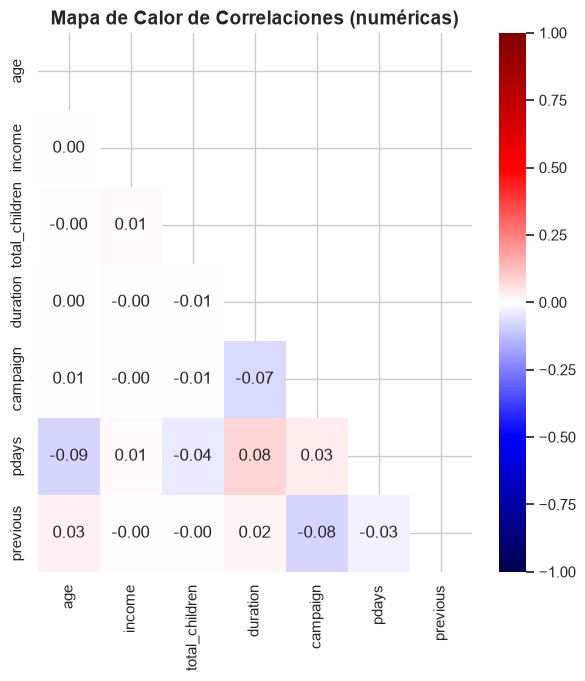

In [10]:
corr_matrix = df_mkt.corr(numeric_only=True)

plt.figure(figsize=corr_matrix.shape)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    annot=True,       
    fmt=".2f",       
    cmap= 'seismic',
    vmin=-1, 
    vmax=1,
    mask=mask   
)

plt.title('Mapa de Calor de Correlaciones (numéricas)', fontsize=14)

plt.show()

Todas las correlaciones son prácticamente 0. La más alt es 0,08 (entre `pdays` y `duration`, y entre `pdays` y `age`), muy por debajodel 0,3 que indicaría una relación moderada.

Las variables numéricas son casi independientes entre sí: la edad no dice nada sobre los ingresos, ni la duración de la llamada sobre cuántas veces se llamó al cliente. Cada variable aporta información distinta y no hay variables repetidas.

Este mapa no incluye la variable objetivo `subscribed`, porque es texto (yes / no) y no se puede correlacionar directamente. Más adelante veremos como infuye la variable `subscribed`con las variables numéricas.

In [11]:
# Clientes con pdays vacío, según su resultado en la campaña anterior
print(pd.crosstab(df_mkt["poutcome"], df_mkt["pdays"].isnull()))

pdays        False  True 
poutcome                 
failure        132   3784
nonexistent      0  32690
success       1261      0


In [12]:
# Cliente contactado antes = tiene un resultado previo (failure o succes)
df_mkt["contactado_antes"] = np.where(df_mkt["poutcome"] == "nonexistent", "no", "yes")

print(df_mkt["contactado_antes"].value_counts())

#comprobamos que coincide con previous (nº de contactos previos)
print(pd.crosstab(df_mkt["contactado_antes"], df_mkt["previous"] > 0))

contactado_antes
no     32690
yes     5177
Name: count, dtype: int64
previous          False  True 
contactado_antes              
no                32690      0
yes                   0   5177


Se crea `contactado_antes`: vale "yes" si `poutcome` es failure o succes, y "no" si es NONEXISTENT. Resultado: 5.177 clientes contactados antes y 32.690 no.

Coincide exactamente con `previous > 0` (el número de contactos antes de esta campaña): no hay ningún cliente en el que ambas variables discrepen.

## 5. Variable objetivo: ¿cuántos clientes contratan el depósito?

Antes de buscar relaciones se mide cuántos clientes contratan el depósito. Este porcentaje es la ***tasa base***, y servirá de referencia para valorar cualquier segmento: un grupo "funciona bien" si supera la tasa base.

                n      %
subscribed              
no          33604  88.74
yes          4263  11.26
Tasa base (subscribed): 11.26%
Tasa base: 11.26 %


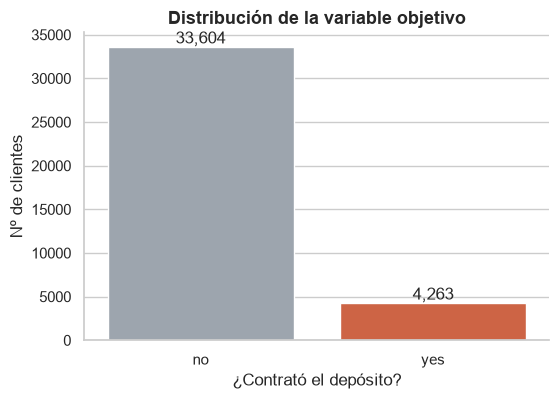

In [13]:
#tabla de frecuencias
conteo = df_mkt["subscribed"].value_counts()                          # Nº de yes / no
porcentaje = df_mkt["subscribed"].value_counts(normalize=True) * 100  # En porcentaje
print(pd.concat([conteo, porcentaje.round(2)], axis=1, keys=["n", "%"]))

# Tasa base guardada para reutilizarla en todos los gráficos 
tasa_base = calcular_tasa_base(df_mkt)
print("Tasa base:", round(tasa_base, 2), "%")

#Gráfico
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_mkt, x="subscribed", hue="subscribed",
              palette=PALETA, legend=False)       # Cada barra con su color fijo
for p in ax.patches:                                  # Etiqueta encima de cada barra
    ax.annotate(f"{p.get_height():,.0f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribución de la variable objetivo")
plt.xlabel("¿Contrató el depósito?")
plt.ylabel("Nº de clientes")
plt.show()

Solo el 11,26 % (4.263 de 37.867 clientes). El 88,74 % restante dice que no. Esta cifra es la tasa base y será la referencia de todo el análisis: un segmento funciona bien si su tasa de conversión supera el 11,26 %, y mal si queda por debajo.

Que la tasa sea tan baja:

Significa que llamar a clientes sin criterio es poco eficiente: de cada 100 llamadas, solo unas 11 terminan en contratación y las otras 89 consumen tiempo y recursos sin resultado. Por eso interesa encontrar segmentos con una tasa mayor, para concentrar ahí el esfuerzo. Además, con un reparto tan desigual, mirar solo cuántos "no" hay no aporta información: lo que importa es comparar la tasa de cada grupo con la base.

## 6. Variables numéricas con `subscribed`

Se comparan las variables numéricas entre los clientes que contratan (`yes`) y los que no (`no`): `age`, `duration` (duración de la llamada en segundos),`campaign` (número de llamadas en esta campaña), `Income` y `total_children`.

In [14]:
numericas = ["age", "duration", "campaign", "income", "total_children","previous"]

#media y mediana de cada variable, separando por yes / no
resumen = df_mkt.groupby("subscribed")[numericas].agg(["mean", "median"]).T.round(2)
resumen   

subscribed                   no       yes
age            mean       39.87     40.90
               median     38.00     37.00
duration       mean      220.69    552.71
               median    163.00    449.00
campaign       mean        2.64      2.06
               median      2.00      2.00
income         mean    93526.85  92823.84
               median  93451.00  91925.00
total_children mean        2.00      2.00
               median      2.00      2.00
previous       mean        0.13      0.49
               median      0.00      0.00

Los clientes que contratan tuvieron de media 0,49 contactos antes de esta campaña frente a 0,13 de los que no, casi cuatro veces más. La mediana es 0 en ambos grupos, lo que indica que la mayoría de los clientes no había sido contactada antes. La diferencia viene de una minoría con contactos previos que contrata mucho más. Esta variable se estudiará con más detalle en la sección de campañas anteriores.

Se dibuja un boxplot por variable, separando a los clientes que contratan (`yes`, naranja) de los que no (`no`, gris).

**Cómo se lee un boxplot:**
- La caja contiene el 50 % central de los clientes.
- La línea dentro de la caja es la mediana.
- Los bigotes llegan hasta los valores más alejados "normales".
- Si las cajas de los dos grupos apenas se solapan, hay diferencia clara. Si están a la misma altura, no la hay.

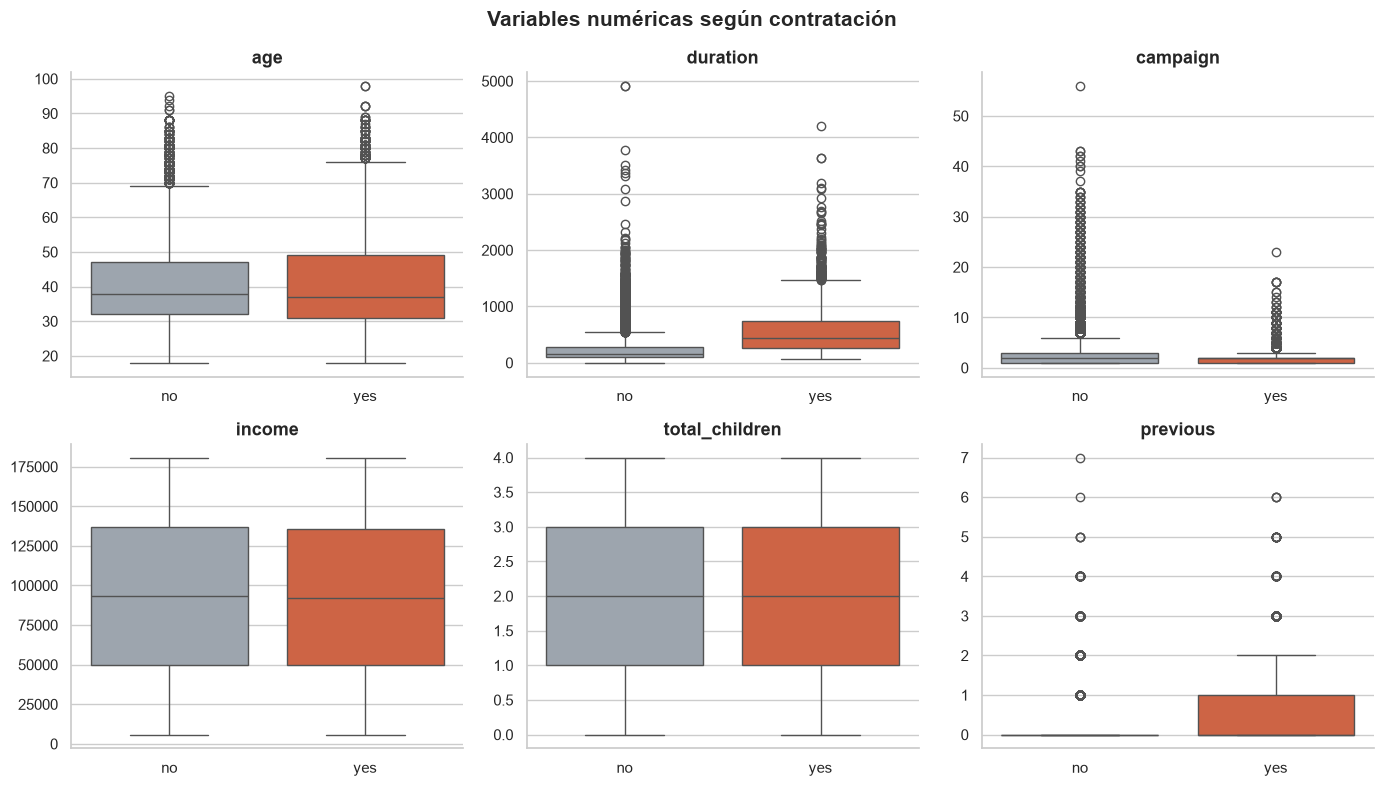

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))   
axes = axes.flatten()                          

for ax, var in zip(axes, numericas):               
    sns.boxplot(data=df_mkt, x="subscribed", y=var, hue="subscribed",palette=PALETA, legend=False, ax=ax) 
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("")


plt.suptitle("Variables numéricas según contratación", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

La variable con más diferencia entre el `yes`y el `no` es la de `duration` (duración de las llamadas), El 50 % central de los clientes que no contratan habla entre unos 100 y 300 segundos, mientras que en los que sí contratan se mueve entre unos 250 y 750 segundos. Los valores
extremos muestran que en ambos grupos hay llamadas de más de 4.000 segundos.

Por lo que al número de contatos que recibe el cliente `campaign` durante la campaña, se puede observar que los que contratan `yes` se concentran entorno a 1 o 2 contactos, aunque los outliers indican que ha habido clientes contactados más de 20 veces.. Mientras que los que no han contratado llega hasta 3 contactos y los outliers muestran que ha habido clientes con mas de 30,40 y hasta más de 50 veces contactados.

En los contactos previos a esta campaña (`previous`), la mayoría de los clientes que no contratan (`no`) no había sido contactada antes. En los que sí contratan (`yes`), la caja sube hasta 1 contacto previo, por lo que es más habitual haber sido contactado antes entre quienes contratan.

Las cajas de `income` y `total_children` están a la misma altura en ambos grupos, por lo que no hay diferencia. En la edad ,`age`, las medianas son parecidas (38 y 37 años), pero los que contratan tienen una caja algo más ancha y bigotes que llegan más arriba (unos 76 años frente a 69), lo que apunta a que puede haber más clientes mayores entre quienes contratan.

### Tests estadísticos

Para comprobar si las diferencias entre los clientes que contratan (`yes`) y los que no (`no`) son reales, se aplican dos tests: la **t de Welch**, que compara las medias de los dos grupos, y **Mann-Whitney**, que compara las distribuciones completas y se ve menos afectado por los valores extremos, algo importante en `duration` y `campaign`. Un p-valor menor que 0,05 indica que la diferencia no parece fruto del azar.

Con tantos clientes, casi cualquier diferencia sale "significativa", así que se añade la **d de Cohen**, que mide el tamaño de la diferencia. Como criterio orientativo, por debajo de 0,2 es insignificante, entre 0,2 y 0,5 pequeña, entre 0,5 y 0,8 mediana y por encima de 0,8 grande.

In [16]:
resultados = []                                          # Aquí guardamos una fila por variable

for var in numericas:
    si = df_mkt.loc[df_mkt["subscribed"] == "yes", var]  # Valores de quienes contratan
    no = df_mkt.loc[df_mkt["subscribed"] == "no", var]   # Valores de quienes no

    _, p_welch = stats.ttest_ind(si, no, equal_var=False)               # t de Welch
    _, p_mw = stats.mannwhitneyu(si, no, alternative="two-sided")       # Mann-Whitney

    resultados.append({"variable": var,
                       "media_yes": round(si.mean(), 2),
                       "media_no": round(no.mean(), 2),
                       "p_welch": formatear_p(p_welch),
                       "p_mannwhitney": formatear_p(p_mw),
                       "d_cohen": round(cohen_d(si, no), 3)})

tabla_num = pd.DataFrame(resultados)
tabla_num = tabla_num.sort_values("d_cohen", key=abs, ascending=False)   # Mayor efecto primero
tabla_num

,variable,media_yes,media_no,p_welch,p_mannwhitney,d_cohen
1,duration,552.71,220.69,< 0.001,< 0.001,1.041
5,previous,0.49,0.13,< 0.001,< 0.001,0.534
2,campaign,2.06,2.64,< 0.001,< 0.001,-0.244
0,age,40.90,39.87,< 0.001,0.046,0.086
3,income,92823.84,93526.85,0.39,0.39,-0.014
4,total_children,2.00,2.00,0.986,0.953,-0.000


### Interpretación de los tests

Los tests confirman lo visto en los boxplots. La duración de la llamada (`duration`) es la variable que más influye en que un cliente se suscriba. Los clientes que sí contratan (`yes`) hablan de media 553 segundos frente a los 221 segundos de los que dicen que no (`no`). El tamaño del efecto (d de Cohen) es de 1,04, lo que significa que el impacto es enorme, y los tests matemáticos aseguran que esta diferencia es 100% real (p-valor menor que 0,001).

El número de llamadas en campañas anteriores (`previous`) tiene un impacto moderado (d = 0,53). Los clientes que compran tenían una media de 0,49 contactos previos frente a los 0,13 de los que no. 

El número de llamadas hechas en esta campaña (`campaign`) muestra un efecto pequeño y negativo(d = -0,24). Los clientes que sí contratan reciben una media de 2,06 llamadas frente a las 2,64 que reciben los que no. Esto indica que llamar mucho quizá no deriva en más contrataciones si no que puede ser que cree el efecto contrario.

La edad (`age`) es un caso engañoso. Los tests dan resultados contradictorios (uno dice que es importante y otro casi no) y el tamaño del efecto es de solo 0,085, lo cual es prácticamente cero. Esta confusión ocurre porque tenemos una base de datos tan grande que los tests estadísticos se vuelven demasiado sensibles a cualquier mínimo detalle. Como además las medias y las medianas van al revés, lo mejor será revisar la edad dividiéndola por tramos más adelante.

Los ingresos (`income`) y el número de hijos (`total_children`) no muestran ninguna diferencia entre los dos grupos (los tests no son significativos y el efecto es cero), por lo que estas variables no influyen en absoluto en la decisión de compra.


### Correlaciones con la variable objetivo

Para incluir `subscribed` en el mapa se convierte a número: 1 si contrata (yes) y 0 si no contrata (no). Así se puede ver, en el mismo gráfico, qué variables numéricas se relacionan con la contratación.

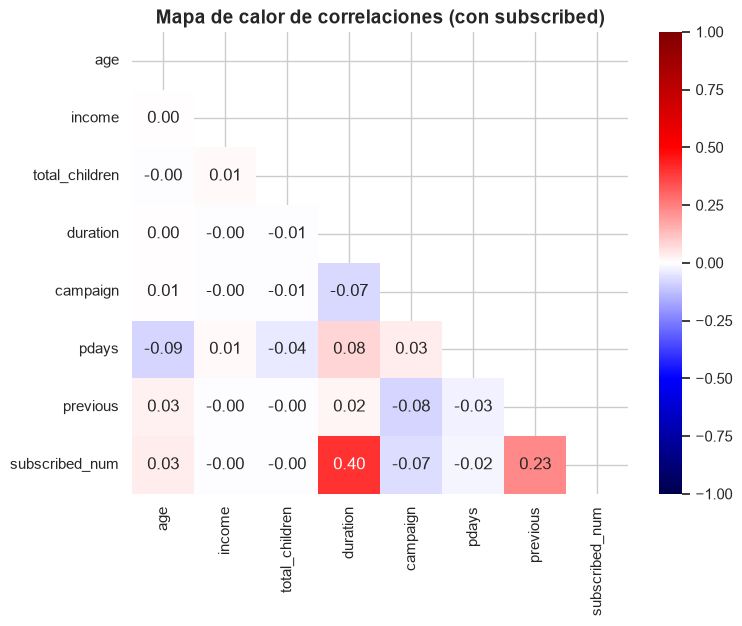

subscribed_num    1.00
duration          0.40
previous          0.23
age               0.03
total_children   -0.00
income           -0.00
pdays            -0.02
campaign         -0.07
Name: subscribed_num, dtype: float64


In [17]:
# Convertimos yes/no en 1/0
df_mkt["subscribed_num"] = (df_mkt["subscribed"] == "yes").astype(int)

corr_matrix2 = df_mkt.corr(numeric_only=True)  

plt.figure(figsize=(8, 6))

mask2 = np.triu(np.ones_like(corr_matrix2, dtype=bool))
sns.heatmap(corr_matrix2, annot=True, fmt=".2f",
            cmap="seismic", vmin=-1, vmax=1, mask=mask2)

plt.title("Mapa de calor de correlaciones (con subscribed)", fontsize=14)
plt.show()

# Solo la fila de subscribed_num, ordenada de mayor a menor
print(corr_matrix2["subscribed_num"].sort_values(ascending=False).round(2))

Aparece una variable nueva: `subscribed_num`. Entre las numéricas sigue sin haber relaciones, pero la fila de la contratación sí muestra una diferencia:`duration` tiene una correlación 0,4 y `previous` tiene correlacion de 0,23 con la contratación,mucho mayor que el resto de variables, que quedan cerca de 0.

Si miramos la última fila del mapa de calor (que es donde tenemos nuestra variable objetivo subscribed_num), la verdad es que pocas variables muestran una relación clara con la contratación:

-`duration` (0,40): Es la que tiene más relación (moderada).

-`previous` (0,23): Muestra una relación pequeña pero positiva.

-El resto (`campaign`, `age`, `income`, `total_children`, `pdays`): Prácticamente rozan el cero o tienen un efecto muy débil (como campaign con -0,07).

Esto encaja bastante con lo que ya nos salía en los tests anteriores: la duración de la llamada y los contactos previos parecen los factores más importantes, mientras que los ingresos o el número de hijos no muestran relación directa.

## 7. Variables categóricas con `subscribed`

En esta sección se analizan las variables categóricas. Para cada una se calcula la tasa de contratación de cada categoría, es decir, el porcentaje de clientes que contrata dentro de ese grupo, y se compara con la tasa base del 11,26 %. Una
categoría "funciona bien" si su tasa supera la base y "funciona mal" si queda por debajo.

### Tipo de contacto (`contact`)

empezamos por el tipo de contacto (`contact`), que indica si se llamó al cliente al móvil (`cellular`) o al teléfono fijo (`telephone`).

In [18]:
# Nº de clientes de cada categoría, separados por yes / no
conteo = pd.crosstab(df_mkt["contact"], df_mkt["subscribed"])

# % de yes / no dentro de cada categoría (cada fila suma 100)
porcentaje = pd.crosstab(df_mkt["contact"], df_mkt["subscribed"], normalize="index") * 100

# Juntamos las dos tablas
tabla_contact = pd.concat([conteo, porcentaje.round(2)], axis=1, keys=["num. clientes", "porcentaje(%)"])
tabla_contact

num. clientes       porcentaje(%)       
subscribed            no   yes            no    yes
contact                                            
cellular           20550  3560         85.23  14.77
telephone          13054   703         94.89   5.11

La tasa del móvil es casi el triple que la del fijo (14,77 / 5,11 ≈ 2,9). Además, de los 4.263 clientes que contratan, 3.560 fueron contactados por móvil.

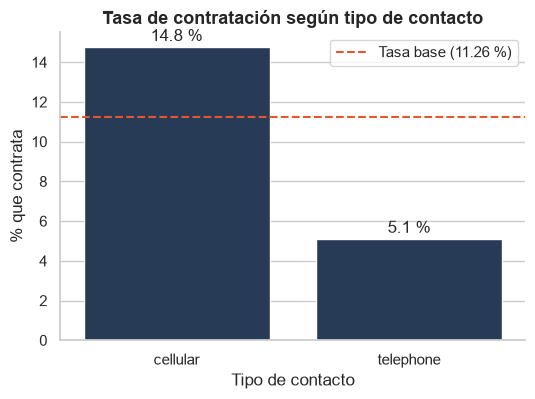

In [19]:
tasa_contact = porcentaje["yes"]                        

plt.figure(figsize=(6, 4))
sns.barplot(x=tasa_contact.index, y=tasa_contact.values,color=COLOR_PRINCIPAL)                     

plt.axhline(tasa_base, color=COLOR_YES, linestyle="--",label=f"Tasa base ({tasa_base:.2f} %)")      # Línea de la tasa base

for i, valor in enumerate(tasa_contact.values):          # valor para cada barra
    plt.text(i, valor + 0.3, f"{valor:.1f} %", ha="center")

plt.title("Tasa de contratación según tipo de contacto")
plt.xlabel("Tipo de contacto")
plt.ylabel("% que contrata")
plt.legend()                                             # Muestra el cuadro de la línea
plt.show()

#### Análisis de (`contact`)

El tipo de contacto marca diferencias bastante claras en los resultados. Si miramos las tasas de conversión:

- Móvil (`cellular`): Alcanza una tasa de contratación del 14,77 %, superando con claridad nuestra tasa base del 11,26 %.
- Teléfono fijo (`telephone`): Se queda en un 5,11 %, menos de la mitad de la media. Al final, la efectividad del móvil es prácticamente el triple.

Además, el canal móvil acumula el peso principal de las conversiones: 3.560 de los 4.263 clientes que contratan (un 83,5 %) vinieron por aquí, a pesar de representar el 64 % del total de la base.

> **💡 Conclusión para marketing:** Los datos apuntan directamente a priorizar y enfocar los esfuerzos en las llamadas a través del móvil frente al teléfono fijo.

### Edad del clietne (`age`)

Como vimos antes, la edad (`age`) es una variable numérica que a primera vista apenas mostraba relación lineal con la contratación. Sin embargo, las medianas iban un poco al revés que las medias, lo que nos da pistas de que podría haber una relación no lineal (en forma de "U" o por grupos de edad concretos).

Para salir de dudas, lo que hacemos es agrupar la edad en seis tramos (`grupo_edad`) y calcular la tasa de contratación de cada uno.

In [20]:
#separamaos la edad en grupos
df_mkt["grupo_edad"] = pd.cut(df_mkt["age"],
                              bins=[17, 25, 35, 45, 55, 65, 100],
                              labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"])


conteo = pd.crosstab(df_mkt["grupo_edad"], df_mkt["subscribed"])

porcentaje = pd.crosstab(df_mkt["grupo_edad"], df_mkt["subscribed"], normalize="index") * 100

tabla_edad = pd.concat([conteo, porcentaje.round(2)], axis=1,keys=["num. clientes", "porcentaje (%)"])

print(tabla_edad)
print('--------------------------------------------------------')
print(df_mkt["grupo_edad"].value_counts().sort_index())

           num. clientes       porcentaje (%)       
subscribed            no   yes             no    yes
grupo_edad                                          
18-25               1230   324          79.15  20.85
26-35              12108  1590          88.39  11.61
36-45              10789  1014          91.41   8.59
46-55               6887   655          91.32   8.68
56-65               2279   415          84.60  15.40
66+                  311   265          53.99  46.01
--------------------------------------------------------
grupo_edad
18-25     1554
26-35    13698
36-45    11803
46-55     7542
56-65     2694
66+        576
Name: count, dtype: int64


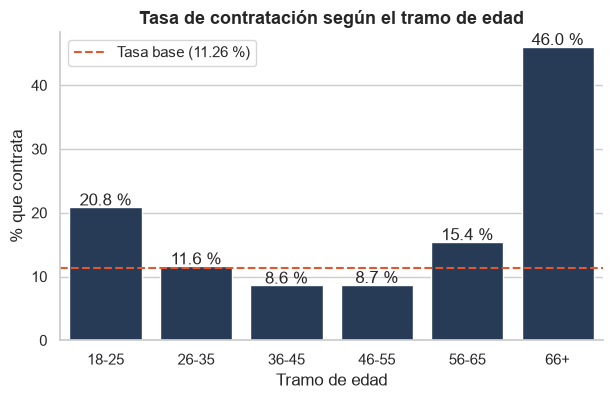

In [21]:
grafico_tasa(df_mkt, "grupo_edad","Tasa de contratación según el tramo de edad", "Tramo de edad")

#### Análisis de `age`

Los tramos se han agrupado de 10 en 10 años, dejando la categoría final abierta (66+) para evitar subgrupos con muy pocos datos.

Al analizar la tasa de contratación por `grupo_edad`, confirmamos lo que sospechábamos: la relación no es lineal, sino que tiene una clara forma de "U":

- Los clientes mayores de 66 años destacan con un 46,01 % de contratación, seguidos por los más jóvenes (18-25 años) con un 20,85 %, ambos muy por encima de la tasa base del 11,26 %.

- Los cliente de 36 a 45 años (8,59 %) y de 46 a 55 años (8,68 %) están claramente por debajo de la media, mientras que el grupo de 26 a 35 años (11,61 %) se mantiene en el promedio. El tramo de 56 a 65 años también repunta un poco (15,40 %).

Esto explica perfectamente por qué el mapa de calor y las métricas anteriores mostraban una correlación casi nula: al no ser una relación en línea recta, los tests tradicionales no la detectaban.

> **💡 Conclusión para para Marketing:** 
>- El grupo de 66+ años tiene la conversión más alta con diferencia, pero es un grupo pequeño en el dataset (576 clientes en total, aportando 265 de ellos contratan, el 6 % del total). 
>- Los tramos de 26 a 45 años, aunque tienen tasas más bajas, representan la mayor parte del volumen: acumulan 2.604 de las 4.263 contrataciones (un 61 % del total) simplemente porque son los grupos más numerosos.



### Trabajo del cliente (`job`)

El trabajo (`job`) indica la ocupación del cliente y tiene 12 categorías.

In [22]:
tabla_job = tabla_tasa(df_mkt, "job")

# Ordenamos de mayor a menor tasa de yes
tabla_job = tabla_job.sort_values(("porcentaje (%)", "yes"), ascending=False)
tabla_job

num. clientes       porcentaje (%)       
subscribed               no   yes             no    yes
job                                                    
student                 553   248          69.04  30.96
retired                1180   392          75.06  24.94
unemployed              810   135          85.71  14.29
admin.                 8316  1248          86.95  13.05
unknown                 268    34          88.74  11.26
management             2394   302          88.80  11.20
technician             5548   680          89.08  10.92
self-employed          1156   141          89.13  10.87
housemaid               892    98          90.10   9.90
entrepreneur           1243   113          91.67   8.33
services               3342   285          92.14   7.86
blue-collar            7902   587          93.09   6.91

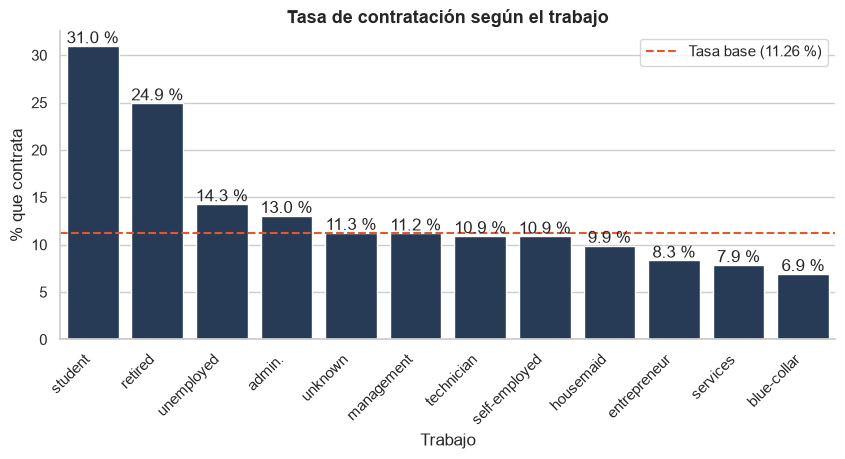

In [23]:
grafico_tasa(df_mkt, "job", "Tasa de contratación según el trabajo", "Trabajo",ordenar=True, rotar=45, ancho=10)

#### Análisis de `job`

Al mirar la profesión (`job`), también vemos diferencias bastante claras en la tasa de contratación:

Los perfiles que más destacan: los estudiantes (`student`, 30,96 %) y los jubilados (`retired`, 24,94 %), muy por encima de la tasa base del 11,26 %. Detrás se sitúan los desempleados (`unemployed`, 14,29 %) y los administrativos (`admin.`, 13,05 %).

En la media: Perfiles como `management`, `technician` o `self-employed` se mueven prácticamente en la media (entre el 10,87 % y el 11,20 %), y la categoría `unknown` calza exactamente con la media (11,26 %).

Por debajo de la media:  `housemaid`, `entrepreneur`, `services` y, con diferencia, los `blue-collar` (6,91 %), que son el perfil que menos contrata de todos.

Los estudiantes y jubilados tienen una contratación muy alta, pero son grupos pequeños: suman 2.373 clientes (el 6 % del total) y aportan 640 de las 4.263 contrataciones (un 15 %).
En cambio, los administrativos (`admin.`) son el grupo más numeroso (9.564 clientes) y aportan 1.248 contrataciones (el 29 % del total), a pesar de tener una menor tasa de contratacion. `blue-collar`, al ser el segundo grupo más grande (8.489 clientes) pero con una tasa tan baja, se quedan en solo 587 contrataciones.

Tiene todo el sentido que los grupos con más contratación (`student` y `retired`) coincidan con los gráficos de `age`, relacionando los estudiantes (`student`) con el grupo más joven (18-25) y los jubilados (`retired`)con el grupo de 66+, que vimos en el análisis anterior.

In [24]:
# Dentro de cada trabajo, % de clientes en cada tramo de edad (cada fila suma 100)
cruce_pct = pd.crosstab(df_mkt["job"], df_mkt["grupo_edad"], normalize="index") * 100
print(cruce_pct.round(1))

print('---------------------------------------------------------')
# Nº de clientes en cada combinación
cruce_n = pd.crosstab(df_mkt["job"], df_mkt["grupo_edad"])
print(cruce_n)

grupo_edad     18-25  26-35  36-45  46-55  56-65   66+
job                                                   
admin.           3.1   44.7   30.4   17.1    4.6   0.1
blue-collar      3.5   33.5   36.6   21.7    4.7   0.1
entrepreneur     1.3   26.4   37.5   26.3    8.1   0.3
housemaid        1.2   17.6   32.8   31.1   14.1   3.1
management       1.2   26.6   34.6   27.3   10.0   0.3
retired          0.0    0.3    2.9   17.7   47.5  31.6
self-employed    3.0   35.5   32.8   21.7    6.9   0.2
services         6.2   40.4   30.5   18.8    4.1   0.0
student         52.6   42.9    4.1    0.4    0.0   0.0
technician       2.7   42.7   32.4   18.0    4.1   0.1
unemployed       3.5   35.3   33.5   21.8    5.5   0.3
unknown          2.3   22.2   27.5   29.1   15.9   3.0
---------------------------------------------------------
grupo_edad     18-25  26-35  36-45  46-55  56-65  66+
job                                                  
admin.           300   4274   2906   1639    436    9
blue-colla

In [25]:
# agrupar student, retired y el resto de trabajos todos juntos
df_mkt["perfil"] = df_mkt["job"].where(df_mkt["job"].isin(["student", "retired"]), "resto")


clientes = pd.crosstab([df_mkt["grupo_edad"], df_mkt["perfil"]],df_mkt["subscribed"]).sum(axis=1)
tasa_yes = pd.crosstab([df_mkt["grupo_edad"], df_mkt["perfil"]],df_mkt["subscribed"], normalize="index")["yes"] * 100

tabla_perfil = pd.concat([clientes, tasa_yes.round(2)], axis=1,keys=["num. clientes", "% yes"])
tabla_perfil

num. clientes  % yes
grupo_edad perfil                       
18-25      resto             1133  15.36
           student            421  35.63
26-35      resto            13349  11.21
           retired              5   0.00
           student            344  27.03
36-45      resto            11725   8.61
           retired             45   4.44
           student             33   9.09
46-55      resto             7260   8.64
           retired            279   9.32
           student              3  66.67
56-65      resto             1948  14.27
           retired            746  18.36
66+        resto               79  48.10
           retired            497  45.67

#### Cruzando edad y trabajo: ¿efecto de la edad o de la profesión?

Para salir de dudas y saber si los estudiantes (`student`) y los jubilados (`retired`) contratan más por su trabajo o por su edad, lo que hacemos es cruzar ambas variables y comparar su tasa de contratación con la del resto de clientes dentro de cada tramo de edad (`grupo_edad`). Eso sí, descartamos las combinaciones con muy pocos clientes (como jubilados jóvenes o estudiantes muy mayores) porque con tan pocos datos las tasas no son fiables.

Al ver los datos:

Los estudiantes aportan información propia, si los comparamos con el resto de personas de su misma edad, contratan bastante más. Un 35,63 % frente al 15,36 % en el tramo de 18 a 25 años, y un 27,03 % frente al 11,21 % entre los 26 y 35. Esto significa que ser estudiante sí que nos aporta un valor extra para predecir la contratación, más allá de los años que tenga.
En los jubilados la diferencia es menor su tasa no se aleja tanto de la del resto de personas de su franja de edad (por ejemplo, de 56 a 65 años tienen un 18,36 % frente al 14,27 %, y a partir de 66 años van prácticamente de la mano). Esto nos indica que la alta contratación de los jubilados se debe fundamentalmente a su edad, no a su puesto de trabajo.


> **💡 Conclusión para marketing:** La edad tiene un peso importante por sí misma con esa forma de "U", y el factor trabajo (`job`) termina de darnos un extra de información muy claro, sobre todo en el caso de los estudiantes.

### Estado civil del cliente (`marital`)

El estado civil (`marital`) indica si el cliente está casado (`married`), soltero (`single`), divorciado (`divorced`) o no consta(`unknown`).

In [26]:
tabla_tasa(df_mkt, "marital")

num. clientes       porcentaje (%)       
subscribed            no   yes             no    yes
marital                                             
divorced            3813   445          89.55  10.45
married            20563  2327          89.83  10.17
single              9162  1480          86.09  13.91
unknown               66    11          85.71  14.29

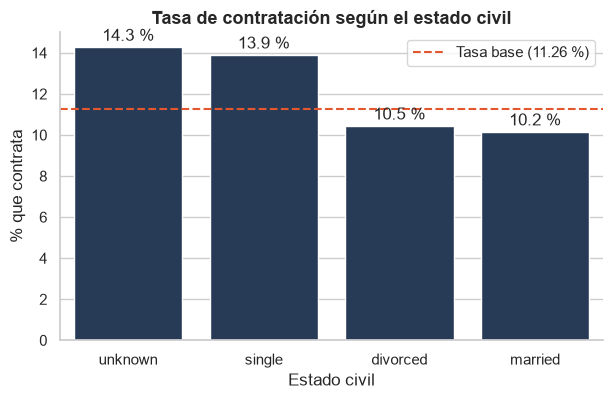

In [27]:
grafico_tasa(df_mkt, "marital", "Tasa de contratación según el estado civil","Estado civil", ordenar=True)

#### Análisis de `marital`

El estado civil muestra diferencias bastante sutiles en la tasa de contratación. Solteros (`single`)son los únicos que superan la tasa base del 11,26 %, alcanzando un 13,91 %. Divorciados (`divorced`) (10,45 %) y casados (`married`) (10,17 %) quedan un poquito por debajo de la media.

La diferencia entre solteros y casados es de apenas 3,7 puntos, una brecha bastante menor que la que veíamos en variables como el tipo de contacto (`contact`) o el trabajo (`job`).

Los solteros aportan 1.480 de las 4.263 contrataciones (el 34,7 %), aunque son el 28,1 % de los clientes, mientras que los casados aportan el 54,6 % de las contrataciones siendo el 60,4 % de los clientes. 

La categoría `unknown` la ignoramos porque apenas tiene 77 clientes y sus datos no son representativos.

Hay que tener cuidado al interpretar esto. Los solteros suelen ser perfiles más jóvenes, y como ya vimos que la edad (`age`) influye mucho en los extremos, es muy probable que parte de esta mayor contratación se deba realmente a la edad y no directamente al estado civil en sí.

### Nivel de estudios del cliente (`education`)


El nivel de estudios (`education`) tiene 8 categorías, desde estudios básicos de 4, 6 y 9 años (`basic.4y`, `basic.6y`, `basic.9y`) hasta estudios universitarios (`university.degree`), pasando por bachillerato (`high.school`) y formación profesional (`professional.course`). Además existen las categorías `illiterate` y `unknown`, que tienen muy pocos clientes.

In [28]:
tabla_edu = tabla_tasa(df_mkt, "education")

tabla_edu = tabla_edu.sort_values(("porcentaje (%)", "yes"), ascending=False)
tabla_edu

num. clientes       porcentaje (%)       
subscribed                     no   yes             no    yes
education                                                    
illiterate                     10     4          71.43  28.57
university.degree           10080  1588          86.39  13.61
unknown                       102    14          87.93  12.07
professional.course          4437   581          88.42  11.58
high.school                  8013  1014          88.77  11.23
basic.4y                     3535   425          89.27  10.73
basic.6y                     1917   170          91.85   8.15
basic.9y                     5510   467          92.19   7.81

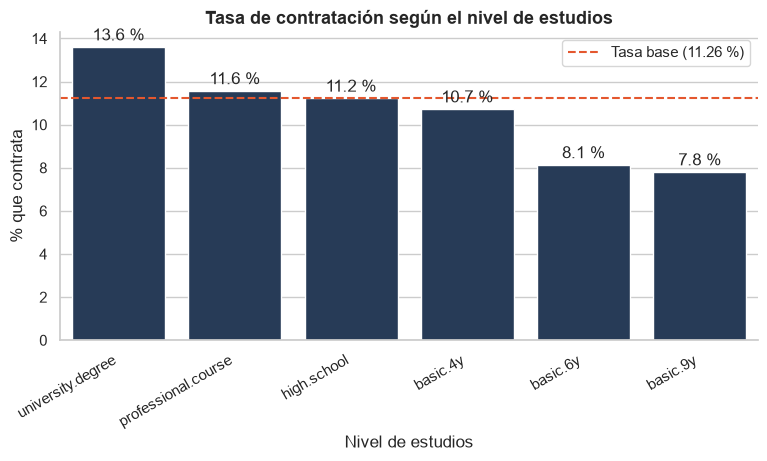

In [29]:
grafico_tasa(df_mkt, "education", "Tasa de contratación según el nivel de estudios","Nivel de estudios", ordenar=True, rotar=30, ancho=9,
             excluir=["illiterate", "unknown"])

#### Análisis de `education`


Los clientes con estudios universitarios (`university.degree`) son los únicos que superan claramente la tasa base del 11,26 %, con un 13,61 %. Los de formación profesional (`professional.course`, 11,58 %) y bachillerato (`high.school`, 11,23 %) están prácticamente en la base, y los de estudios básicos quedan por debajo: `basic.4y` (10,73 %), `basic.6y` (8,15 %) y `basic.9y` (7,81 %). Hay una tendencia general a que más estudios impliquen más contratación.

Los clientes con estudios universitarios aportan 1.588 de las 4.263 contrataciones, lo que supone el 37,3 % del total siendo el 30,8 % de los clientes. Por su parte, los de `basic.9y` aportan 467 contratos (el 11,0 %) siendo el 15,8 % de la base.

Las categorías `illiterate` (14 clientes, 4 contratos) y `unknown` (116 clientes, 14 contratos) no se muestran en el gráfico ni se interpretan porque tienen muy pocos clientes y sus tasas no son fiables.


### Situación financiara del cliente (`default`, `housing`, `loan`)

Se analizan tres variables sobre la situación financiera del cliente: si tiene impagos de crédito (`default`), si tiene hipoteca (`housing`) y si tiene un préstamo personal (`loan`). Las tres toman los valores `yes`, `no` o `unknown`.

In [30]:
tabla_tasa(df_mkt, "default")

num. clientes       porcentaje (%)       
subscribed            no   yes             no    yes
default                                             
no                 26136  3854          87.15  12.85
unknown             7466   409          94.81   5.19
yes                    2     0         100.00   0.00

In [31]:
tabla_tasa(df_mkt, "housing")

num. clientes       porcentaje (%)       
subscribed            no   yes             no    yes
housing                                             
no                 15246  1871          89.07  10.93
unknown              819    93          89.80  10.20
yes                17539  2299          88.41  11.59

In [32]:
tabla_tasa(df_mkt, "loan")

num. clientes       porcentaje (%)       
subscribed            no   yes             no    yes
loan                                                
no                 27659  3537          88.66  11.34
unknown              819    93          89.80  10.20
yes                 5126   633          89.01  10.99

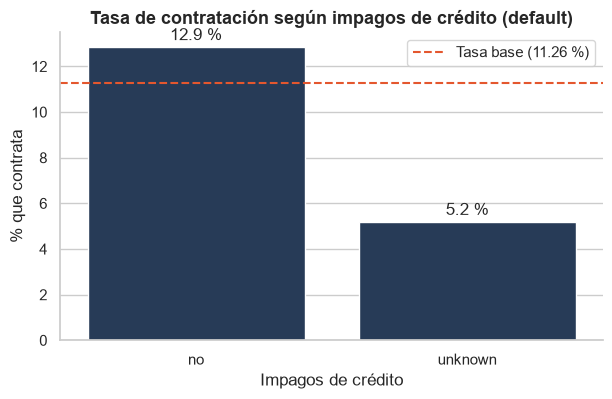

In [33]:
grafico_tasa(df_mkt, "default", "Tasa de contratación según impagos de crédito (default)",
             "Impagos de crédito", ordenar=True, excluir=["yes"])

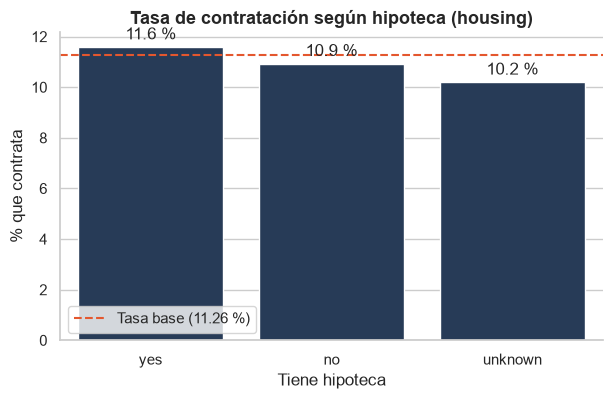

In [34]:
grafico_tasa(df_mkt, "housing", "Tasa de contratación según hipoteca (housing)",
             "Tiene hipoteca", ordenar=True)

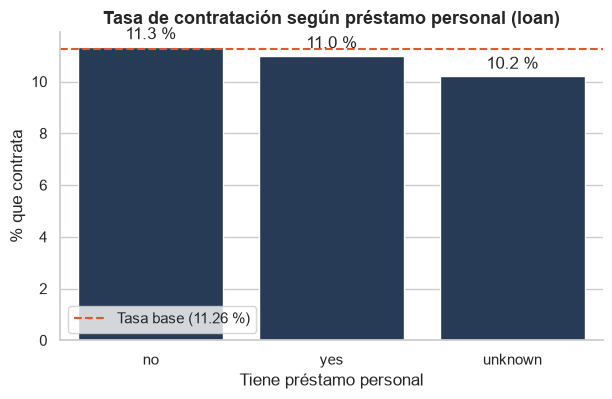

In [35]:
grafico_tasa(df_mkt, "loan", "Tasa de contratación según préstamo personal (loan)",
             "Tiene préstamo personal", ordenar=True)

#### Análisis de `default`, `housing`, `loan`

De las tres variables sobre la situación financiera, solo los impagos de crédito (`default`) muestran una diferencia clara. Los clientes con `default = no` contratan en el 12,85 % de los casos, algo por encima de la tasa base del 11,26 %, mientras que los clientes con `default = unknown` (se desconoce si tienen impagos) contratan solo el 5,19 %, menos de la mitad. Este grupo es grande: 7.875 clientes (el 20,8 % del total), que aportan 409 de las 4.263 contrataciones (el 9,6 %). La categoría `default = yes` solo tiene 2 clientes y no se interpreta.

La hipoteca (`housing`) y el préstamo personal (`loan`) apenas se diferencian de la tasa base. Entre quienes tienen hipoteca y quienes no, la tasa de contratación (11,59 % y 10,93 %) difiere en menos de un punto, y entre quienes tienen préstamo personal y quienes no (10,99 % y 11,34 %) la diferencia es aún menor. En ambas variables hay 912 clientes con valor desconocido (`unknown`), con una tasa del 10,20 %. Por tanto, tener una hipoteca o un préstamo no parece influir en la contratación del depósito.

### Nivel de ingresos del cliente (`income_level`)

El nivel de ingresos (`income_level`) se creó en la fase de limpieza dividiendo a los clientes en cuatro grupos según los cuartiles de su ingreso (`income`): `low` (menos de 49.728,5), `medium` (de 49.728,5 a 93.316), `medium-high` (de 93.316 a 136.935) y `high` (136.935 o más).

In [36]:
df_mkt.groupby("income_level")["income"].agg(["count", "min", "max"])

,count,min,max
income_level,,,
high,9467,136936,180802
low,9467,5841,49728
medium,9466,49729,93313
medium-high,9467,93316,136934


In [37]:
orden_ingresos = ["low", "medium", "medium-high", "high"] 
df_mkt["income_level"] = pd.Categorical(df_mkt["income_level"],categories=orden_ingresos, ordered=True)

tabla_tasa(df_mkt, "income_level")

num. clientes       porcentaje (%)       
subscribed              no   yes             no    yes
income_level                                          
low                   8404  1063          88.77  11.23
medium                8364  1102          88.36  11.64
medium-high           8404  1063          88.77  11.23
high                  8432  1035          89.07  10.93

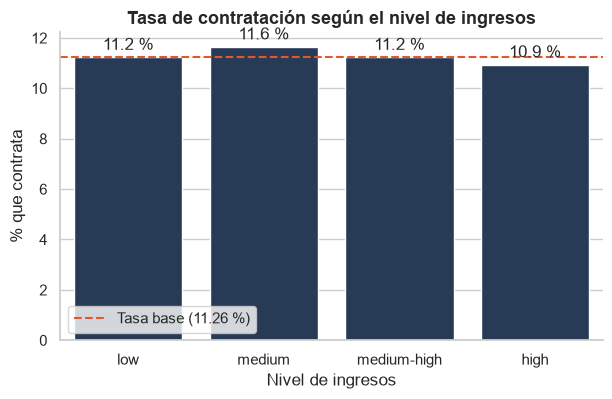

In [38]:
grafico_tasa(df_mkt, "income_level", "Tasa de contratación según el nivel de ingresos","Nivel de ingresos")

#### Análisis `income_level`

El nivel de ingresos (`income_level`) no muestra diferencias relevantes en la tasa de contratación. Los cuatro grupos tienen casi el mismo tamaño porque se crearon a partir de cuartiles, y sus tasas se mueven en menos de un punto, entre el 10,93 % de `high` y el 11,64 % de `medium`, todas cerca de la tasa base del 11,26 %. Cada grupo aporta alrededor del 25 % de las contrataciones (entre 1.035 y 1.102 de las
4.263). Tampoco hay una tendencia: los clientes con más ingresos no contratan ni
más ni menos que los de menos ingresos.

Para marketing, el nivel de ingresos no parece una variable útil para decidir a quién llamar.

### Test estadísticos

Para comparar todas las variables categóricas se aplica a cada una el test Chi-cuadrado, que indica si existe relación con la contratación (`subscribed`), y la V de Cramér, que mide su fuerza en una escala de 0 (ninguna relación) a 1 (relación total). Como criterio orientativo, por debajo de 0,1 la relación es insignificante, entre 0,1 y 0,3 pequeña, entre 0,3 y 0,5 mediana y por encima de 0,5 grande. Con tantos clientes en la base de datos casi todo sale estadísticamente significativo (p < 0,05), por eso se da mucha más importancia al valor de la V de Cramér para ver qué variables importan de verdad.

Por otro lado, se excluyen de este cálculo las categorías que tienen muy pocos clientes (como `default` = yes con solo 2 casos, e `illiterate` con 14), porque el test no es fiable cuando se trabaja con tan pocos datos.

In [39]:
from scipy.stats import chi2_contingency              # Test Chi-cuadrado

categoricas = ["contact", "grupo_edad", "job", "marital", "education",
               "default", "housing", "loan", "income_level","poutcome"]

# Categorías con muy pocos clientes que quitamos de cada variable
excluir = {"default": ["yes"], "education": ["illiterate"]}

def lectura_v(v):
    if v < 0.1:
        return "Insignificante"
    elif v < 0.3:
        return "Pequeña"
    elif v < 0.5:
        return "Mediana"
    return "Grande"

resultados = []                                        # Aquí guardamos una fila por variable

for variable in categoricas:
    tabla = pd.crosstab(df_mkt[variable], df_mkt["subscribed"])   # Recuento de clientes
    tabla = tabla.drop(excluir.get(variable, []))                 # Quitamos categorías pequeñas

    chi2, p, _, _ = chi2_contingency(tabla)            # Nos quedamos con chi2 y p
    n = tabla.sum().sum()                              # Total de clientes de la tabla
    k = min(tabla.shape) - 1                           # Filas o columnas menos 1 (la menor)
    v = (chi2 / (n * k)) ** 0.5                        # V de Cramér

    resultados.append({"variable": variable,
                       "chi2": round(chi2, 1),
                       "p_valor": formatear_p(p),
                       "V_cramer": round(v, 3),
                       "lectura": lectura_v(v)})

tabla_cat = pd.DataFrame(resultados).sort_values("V_cramer", ascending=False)
tabla_cat

,variable,chi2,p_valor,V_cramer,lectura
9,poutcome,3856.6,< 0.001,0.319,Mediana
1,grupo_edad,1021.3,< 0.001,0.164,Pequeña
2,job,861.7,< 0.001,0.151,Pequeña
0,contact,816.4,< 0.001,0.147,Pequeña
5,default,365.3,< 0.001,0.098,Insignificante
4,education,157.6,< 0.001,0.065,Insignificante
3,marital,105.6,< 0.001,0.053,Insignificante
6,housing,5.0,0.081,0.012,Insignificante
8,income_level,2.4,0.491,0.008,Insignificante
7,loan,1.6,0.441,0.007,Insignificante


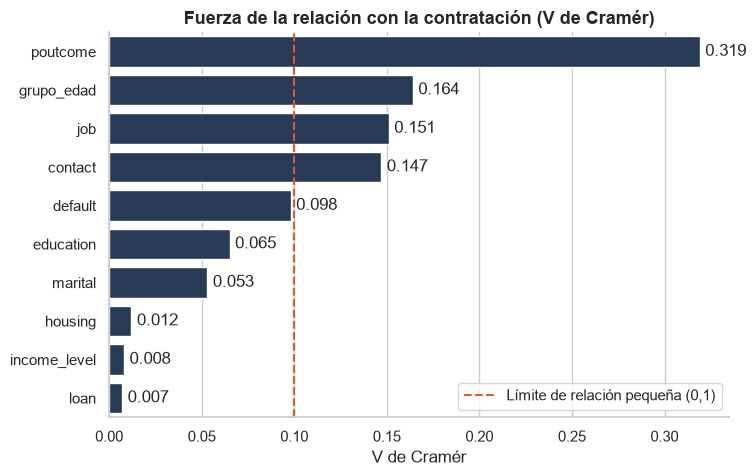

In [40]:
plt.figure(figsize=(8, 5))
sns.barplot(data=tabla_cat, x="V_cramer", y="variable", color=COLOR_PRINCIPAL)

plt.axvline(0.1, color=COLOR_YES, linestyle="--",
            label="Límite de relación pequeña (0,1)")     

for i, v in enumerate(tabla_cat["V_cramer"]):              
    plt.text(v + 0.003, i, f"{v:.3f}", va="center")

plt.title("Fuerza de la relación con la contratación (V de Cramér)")
plt.xlabel("V de Cramér")
plt.ylabel("")
plt.legend()
plt.show()

### Interpretación de los test

Al analizar la relación de las variables categóricas con la contratación, vemos que los factores con mayor peso son el resultado de la campaña anterior (`poutcome`, V = 0,32), el tramo de edad (`grupo_edad`, V = 0,164), el tipo de trabajo (`job`, V = 0,151) y el canal de contacto (`contact`, V = 0,147). `poutcome` es la única con una relación mediana (entre 0,3 y 0,5) y destaca con claridad sobre las demás, que tienen una relación pequeña.

Otras tres variables —impagos (`default`), estudios (`education`) y estado civil (`marital`)— devuelven p-valores significativos (p < 0,001), pero sus valores de V no alcanzan el 0,1. Pasa algo similar a lo que vimos con la edad numérica: al trabajar con un volumen de datos tan grande, pequeñas variaciones salen estadísticamente significativas aunque su impacto práctico sea reducido.

En el extremo opuesto, la hipoteca (`housing`), el préstamo personal (`loan`) y el nivel de ingresos (`income_level`) no muestran ninguna relación con la conversión (p > 0,05 y V < 0,02), por lo que no aportan valor predictivo para seleccionar a qué clientes contactar.

Por último, conviene recordar que una V global baja no descarta la presencia de nichos concretos muy rentables. El grupo de 66 años o más, por ejemplo, convierte al 46,01 % (cuatro veces la tasa base), pero al ser 576 clientes su impacto se diluye en la métrica general. Por eso pasaremos a analizar segmentos específicos más adelante.

### Conclusiones para marketing


- **Canal:** los clientes contactados por móvil (`cellular`) contratan el 14,77 %, casi el triple que los contactados por teléfono fijo (`telephone`, 5,11 %).
- **Edad:** la relación tiene forma de "U". Contratan más los clientes de 66 o más años (46,01 %) y los de 18 a 25 (20,85 %), y menos los de 36 a 55 (en torno al 8,6 %).
- **Trabajo:** los estudiantes (`student`, 30,96 %) y los jubilados (`retired`, 24,94 %) son los perfiles que más contratan y los `blue-collar` (6,91 %) los que menos. Dentro de su misma edad, los estudiantes siguen contratando más que el resto, mientras que en los jubilados la diferencia se explica sobre todo por la edad.
- **Estudios y estado civil:** diferencias pequeñas. Los clientes con estudios universitarios contratan algo más (13,61 %) y los de estudios básicos de 9 años menos (7,81 %). Los solteros superan algo la tasa base (13,91 %).
- **Impagos:** los clientes con el dato de `default` ausente contratan solo el 5,19 %, frente al 12,85 % de los que tienen `default = no`, y la diferencia se mantiene dentro de cada canal.
- **Situación financiera e ingresos:** la hipoteca (`housing`), el préstamo personal (`loan`) y el nivel de ingresos (`income_level`) no se relacionan con la contratación.

## 8. ¿Cuál es el mejor momento para realizar la llamada?

Analizaremos si la tasa de contratación cambia según el año y el mes de la llamada (`date`), para ver si hay épocas más favorables para lanzar una campaña. La variable tiene 214 valores ausentes (el 0,6 %), que se excluyen de este análisis.

In [41]:
#convertimos date a fecha y los "unknown" pasan a NaT.
df_mkt["date"] = pd.to_datetime(df_mkt["date"], errors="coerce")

print("Fechas 'unknown':", df_mkt["date"].isna().sum()) 
print("Primera fecha:", df_mkt["date"].min())
print("Última fecha:", df_mkt["date"].max())

# Sacamos el año y el mes de cada fecha
df_mkt["año"] = df_mkt["date"].dt.year
df_mkt["mes"] = df_mkt["date"].dt.month        # 1 = enero ... 12 = diciembre

tabla_tasa(df_mkt, "año")                      # Clientes y tasa de contratación por año

Fechas 'unknown': 214
Primera fecha: 2015-01-01 00:00:00
Última fecha: 2019-12-31 00:00:00


num. clientes      porcentaje (%)       
subscribed            no  yes             no    yes
año                                                
2015.0              6706  824          89.06  10.94
2016.0              6634  870          88.41  11.59
2017.0              6666  829          88.94  11.06
2018.0              6687  856          88.65  11.35
2019.0              6725  856          88.71  11.29

In [42]:
#quitamos el .0 de los años con el astype
df_mkt["año"] = df_mkt["date"].dt.year.astype("Int64")
df_mkt["mes"] = df_mkt["date"].dt.month.astype("Int64")

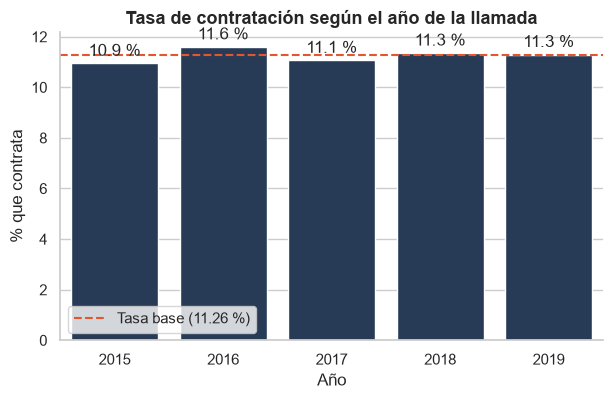

In [43]:
grafico_tasa(df_mkt, "año", "Tasa de contratación según el año de la llamada", "Año")

El año de la llamada no muestra diferencias en la tasa de contratación. Los cinco años (de 2015 a 2019) tienen casi el mismo número de clientes, unos 7.500 cada uno, y su tasa de contratación se mueve entre el 10,94 % (2015) y el 11,59 % (2016), siempre cerca de la tasa base del 11,26 %. No hay una tendencia creciente ni decreciente, por lo que el año no ayuda a decidir cuándo lanzar una campaña.

#### ¿En que meses funcionan mejor las llamadas?

COmo con el año no se han visto muchas diferencias, vamos a comprobar en que meses se ha contratado más.

In [44]:
df_mkt["date"].value_counts().head(8)

date
2016-02-28    86
2018-02-28    83
2015-02-28    82
2017-02-28    82
2019-02-28    71
2018-04-30    53
2017-09-30    49
2018-11-30    47
Name: count, dtype: int64

In [45]:
tabla_tasa(df_mkt, "mes")

num. clientes      porcentaje (%)       
subscribed            no  yes             no    yes
mes                                                
1                   2734  354          88.54  11.46
2                   2820  350          88.96  11.04
3                   2823  339          89.28  10.72
4                   2793  350          88.86  11.14
5                   2817  331          89.49  10.51
6                   2745  351          88.66  11.34
7                   2784  358          88.61  11.39
8                   2763  368          88.25  11.75
9                   2844  325          89.74  10.26
10                  2781  384          87.87  12.13
11                  2786  374          88.16  11.84
12                  2728  351          88.60  11.40

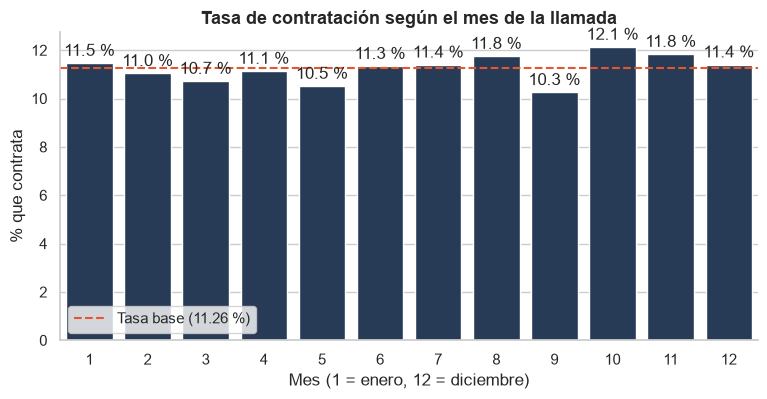

In [46]:
grafico_tasa(df_mkt, "mes", "Tasa de contratación según el mes de la llamada","Mes (1 = enero, 12 = diciembre)", ancho=9)

El mes de la llamada tampoco muestra diferencias claras en la tasa de contratación. Cada mes tiene unos 3.100 clientes, y las tasas se mueven entre el 10,26 % (septiembre) y el 12,13 % (octubre), siempre cerca de la tasa base del 11,26 %. Por tanto, ni el año ni el mes permiten decidir cuándo lanzar una campaña.

El momento de la llamada no parece relacionado con la contratación.

#### Conlusiones para marketing

- **Año:** la tasa de contratación es estable entre 2015 y 2019, entre el 10,94 % y el 11,59 %.
- **Mes:** las tasas de los doce meses se mueven entre el 10,26 % y el 12,13 %. Aunque se observa que el 28 de febrero hay muchos mas clientes.
- El momento de la llamada no es un factor que ayude a decidir cuándo contactar. Conviene centrar el esfuerzo en a quién llamar y por qué canal.

## 9. Historial de contactos: campañas anteriores, insistencia y duración

### 9.1 Campañas anteriores (`poutcome` y `previous`)

Analizaremos el resultado de la campaña anterior (`poutcome`) y su relación con la contratación. La variable tiene tres valores: `NONEXISTENT` (el cliente no fue contactado en ninguna campaña anterior), `FAILURE` (fue contactado y no contrató) y `SUCCESS` (fue contactado y contrató).

In [47]:
tabla_tasa(df_mkt, "poutcome")

num. clientes       porcentaje (%)       
subscribed             no   yes             no    yes
poutcome                                             
failure              3357   559          85.73  14.27
nonexistent         29804  2886          91.17   8.83
success               443   818          35.13  64.87

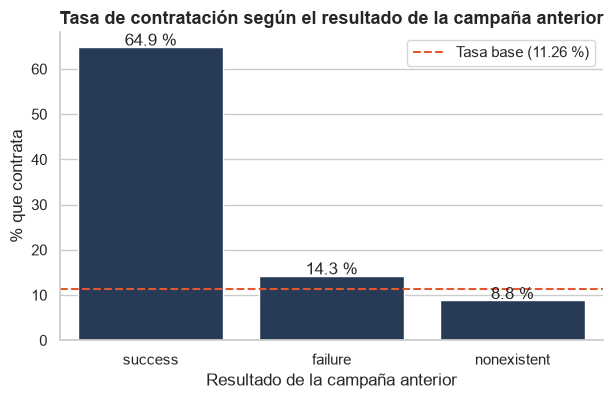

In [48]:
grafico_tasa(df_mkt, "poutcome", "Tasa de contratación según el resultado de la campaña anterior",
             "Resultado de la campaña anterior", ordenar=True)

#### Conclusiones para marketing

- El resultado de la campaña anterior (`poutcome`) es la variable categórica más relacionada con la contratación. Los clientes con éxito previo (`success`) contratan en el 64,87 % de los casos, casi seis veces la tasa base del 11,26 %. Los que fueron contactados y no contrataron (`failure`) contratan el 14,27 %, algo por encima de la base, y los que no habían sido contactados antes (`nonexistent`) solo el 8,83 %.

- Los clientes con éxito previo son solo el 3,3 % del total (1.261 clientes), pero aportan 818 de las 4.263 contrataciones (el 19,2 %). Los clientes `nonexistent` son el 86,3 % y aportan 2.886 contrataciones (el 67,7 %), por lo que siguen siendo la mayor fuente de contrataciones.

- Los clientes con éxito previo son el grupo prioritario por su tasa, aunque es un grupo pequeño.

#### ¿Importa el número de contactos previos?

En el punto 6, se vió que los clientes que contratan tuvieron de media más contactos antes de esta campaña (`previous`) que los que no. Ya se comprobó también que haber sido contactado antes se asocia a contratar más (`poutcome`). Ahora se mira si importa cuántas veces se contactó al cliente. Como la mayoría de los clientes tiene 0 contactos previos y los valores altos son muy raros, se agrupan en
cuatro tramos (`previous_gr`): 0, 1, 2 y 3 o más.

In [49]:
#agrrupamos previous en cuatro tramos: 0, 1, 2 y 3 o más
df_mkt["previous_gr"] = pd.cut(df_mkt["previous"], bins=[-1, 0, 1, 2, 10], labels=["0", "1", "2", "3 o más"])

tabla_tasa(df_mkt, "previous_gr")

num. clientes       porcentaje (%)       
subscribed             no   yes             no    yes
previous_gr                                          
0                   29804  2886          91.17   8.83
1                    3309   891          78.79  21.21
2                     372   317          53.99  46.01
3 o más               119   169          41.32  58.68

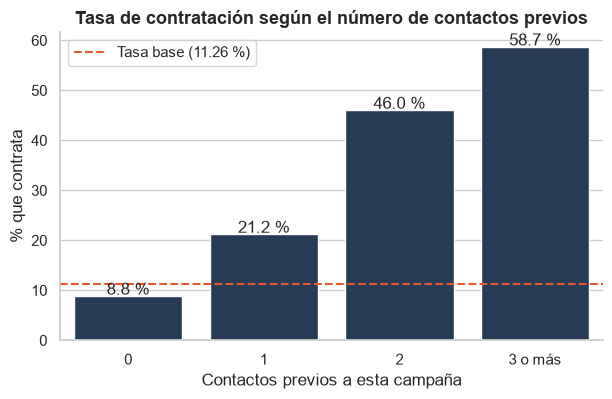

In [50]:
grafico_tasa(df_mkt, "previous_gr", "Tasa de contratación según el número de contactos previos", "Contactos previos a esta campaña")

#### Conclusiones del gráfico

El número de contactos previos a esta campaña (`previous`) está claramente relacionado con la contratación, como se puede ver en el gráfico, la tasa sube en cada tramo.

Hay que distinguir entre tasa y volumen. Los clientes con dos o más contactos previos son muy pocos (977 clientes, el 2,6 % del total) y aportan 486 de las 4.263 contrataciones (el 11,4 %). Los clientes sin contactos previos siguen aportando la mayor parte de las contrataciones (2.886, el 67,7 %), aunque con una tasa baja.

Los clientes con más contactos previos pueden ser, en buena parte, los que ya contrataron en la campaña anterior (`poutcome = success`), deberemos mirar si es esa la razón.

#### ¿El número de contactos previo aporta información por si mismo?

Los clientes con más contactos previos (`previous`) contratan más, pero también pueden ser los que tuvieron éxito en la campaña anterior (`poutcome = success`), que ya mostraban una tasa muy alta. Para comprobarlo, se compara el número de contactos previos (`previous_gr`) dentro de cada resultado anterior, solo entre los clientes contactados antes. Se excluye `nonexistent`, porque todos sus clientes tienen 0
contactos previos.

In [51]:
#quitamos lo no contactados previamente
contactados = df_mkt[df_mkt["poutcome"].str.lower() != "nonexistent"]


clientes = pd.crosstab([contactados["poutcome"], contactados["previous_gr"]],
                       contactados["subscribed"]).sum(axis=1)

# tasa de yes en las combinaciones
tasa_yes = pd.crosstab([contactados["poutcome"], contactados["previous_gr"]],
                       contactados["subscribed"], normalize="index")["yes"] * 100

tabla_previous = pd.concat([clientes, tasa_yes.round(2)], axis=1, keys=["num. clientes", "% yes"])
tabla_previous[tabla_previous["num. clientes"] > 0]       # Quitamos las combinaciones vacías

num. clientes  % yes
poutcome previous_gr                      
failure  1                     3401  12.20
         2                      397  25.19
         3 o más                118  37.29
success  1                      799  59.57
         2                      292  74.32
         3 o más                170  73.53

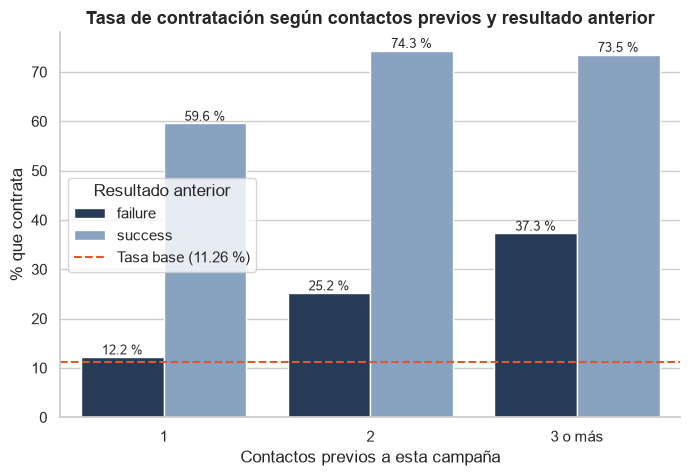

In [52]:
# Pasamos la tabla a formato normal (las columnas de índice pasan a ser columnas)
datos = tabla_previous[tabla_previous["num. clientes"] > 0].reset_index()
datos = datos.rename(columns={"% yes": "tasa_yes"})

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=datos, x="previous_gr", y="tasa_yes", hue="poutcome",
                 order=["1", "2", "3 o más"],
                 hue_order=["failure", "success"],
                 palette=[COLOR_PRINCIPAL, "#7FA1C9"])

for contenedor in ax.containers:                      # Escribe el valor encima de cada barra
    ax.bar_label(contenedor, fmt="%.1f %%", fontsize=9)

plt.axhline(tasa_base, color=COLOR_YES, linestyle="--",
            label=f"Tasa base ({tasa_base:.2f} %)")   # Línea de la tasa base
plt.title("Tasa de contratación según contactos previos y resultado anterior")
plt.xlabel("Contactos previos a esta campaña")
plt.ylabel("% que contrata")
plt.legend(title="Resultado anterior")
plt.show()

Al comparar el número de contactos previos (`previous_gr`) dentro de cada resultado de la campaña anterior (`poutcome`), se ve que ambas variables aportan información. Entre los clientes con `failure`, la tasa de contratación sube en cada tramo: 12,20 % con un contacto, 25,19 % con dos y 37,29 % con tres o más. Entre los clientes con `success`, sube de 59,57 % con un contacto a 74,32 % con dos, y después se mantiene (73,53 % con tres o más). Se puede ver que más contactos equivale a mas contratación. 

También se puede ver que importa más que hayan contratado antes, porque las tasas de contratación, son mucho más altas cuando habian cotratado antes que cuando no.

### 9.2 Contactos durante esta campaña (`campaign`)

En la sección 6, en al variables numéricas, se vio que los clientes que contratan reciben de media menos contactos durante esta campaña (`campaign`) que los que no (2,06 frente a 2,64). Para saber a partir de cuántos contactos deja de compensar insistir, se agrupan en seis
tramos (`campaign_gr`): de 1 a 5 contactos por separado y un último tramo de 6 o más, porque los valores altos son muy raros (el máximo llega a 56).

In [53]:
df_mkt["campaign_gr"] = pd.cut(df_mkt["campaign"],
                               bins=[0, 1, 2, 3, 4, 5, 100],
                               labels=["1", "2", "3", "4", "5", "6 o más"])

tabla_tasa(df_mkt, "campaign_gr")

num. clientes       porcentaje (%)       
subscribed             no   yes             no    yes
campaign_gr                                          
1                   14088  2093          87.07  12.93
2                    8585  1125          88.41  11.59
3                    4408   536          89.16  10.84
4                    2211   222          90.88   9.12
5                    1352   114          92.22   7.78
6 o más              2960   173          94.48   5.52

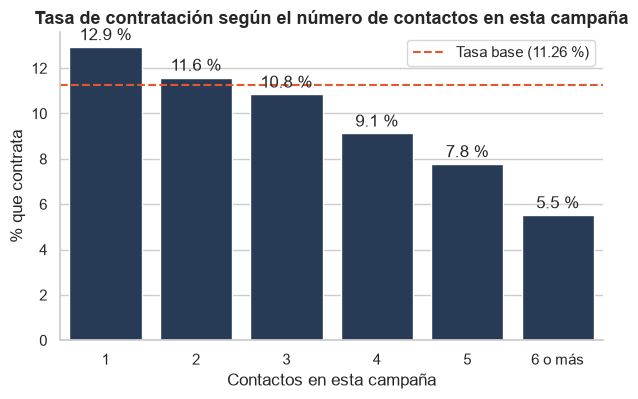

In [54]:
grafico_tasa(df_mkt, "campaign_gr", "Tasa de contratación según el número de contactos en esta campaña", "Contactos en esta campaña")

#### Conclusiones del gráfico

Al analizar los contactos realizados en la campaña actual (`campaign_gr`), se observa una relación clara: a mayor número de llamadas, menor es la tasa de contratación.

Los clientes contactados una sola vez tienen la tasa de conversión más alta, con un 12,93 % (2.093 contrataciones de 16.181 clientes en ese grupo). En el segundo y tercer contacto las tasas se mantienen cercanas a la media global (11,59 % y 10,84 % respectivamente). A partir de la cuarta llamada la efectividad cae de forma continua: 9,12 % con 4 contactos, 7,78 % con 5, y un 5,52 % para el grupo de 6 o más contactos.

La inmensa mayoría de las contrataciones se concentran en las primeras llamadas. Los clientes contactados entre 1 y 3 veces acumulan 3.481 de las 4.263 contrataciones totales (el 81,7 % del total de conversiones). En cambio, realizar 6 o más intentos exige un esfuerzo considerable para obtener solo 173 contrataciones (un 4,1 % del total).

#### Conclusiones para marketing

Tres de cada cuatro contrataciones (3.218 de las 4.263, el 75,5 %) se consiguen en los dos primeros contactos, que concentran el 68,4 % de los clientes.
La insistencia repetida muestra un mal rendimiento. Centrar la estrategia en los primeros contactos permite maximizar las contrataciones y reducir el volumen de llamadas con poca probabilidad de éxito.

### 9.4 La duración de las llamadas (`duration`)

La duración de la llamada (`duration`, en segundos) fue en la sección 6 la variable más relacionada con la contratación: los clientes que contratan hablan de media 553 segundos frente a 221 los que no. Para ver cómo cambia la tasa de contratación según la duración, se agrupa en seis tramos (`duration_gr`): hasta 1 minuto, de 1 a 2, de 2 a 3, de 3 a 5, de 5 a 10 y más de 10 minutos. Se calcula la tasa de contratación de cada tramo y se mira cuántos clientes hay en cada uno.

Hay que recordar que la duración solo se conoce cuando la llamada termina, por lo que sirve para describir lo ocurrido, pero no para decidir a quién llamar.

In [55]:
df_mkt["duration_gr"] = pd.cut(df_mkt["duration"],
                               bins=[-1, 60, 120, 180, 300, 600, 5000],
                               labels=["0-60 s", "61-120 s", "121-180 s",
                                       "181-300 s", "301-600 s", "más de 600 s"])

tabla_tasa(df_mkt, "duration_gr")

num. clientes       porcentaje (%)       
subscribed              no   yes             no    yes
duration_gr                                           
0-60 s                3945     0         100.00   0.00
61-120 s              7790   150          98.11   1.89
121-180 s             6821   367          94.89   5.11
181-300 s             7632   866          89.81  10.19
301-600 s             5795  1346          81.15  18.85
más de 600 s          1621  1534          51.38  48.62

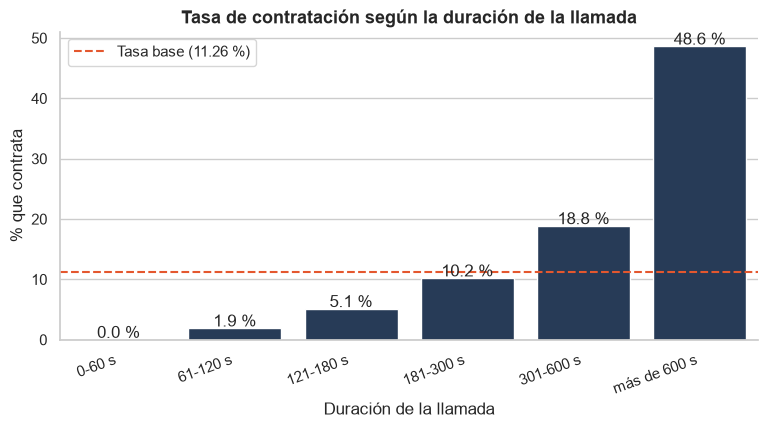

In [56]:
grafico_tasa(df_mkt, "duration_gr", "Tasa de contratación según la duración de la llamada",
             "Duración de la llamada", rotar=20, ancho=9)

#### Conclusiones del gráfico

La duración de la llamada está muy relacionada con la contratación y la tasa sube en cada tramo. Ninguno de los 3.945 clientes con llamadas de hasta un minuto contrata, y la tasa es del 1,89 % entre 1 y 2 minutos y del 5,11 % entre 2 y 3. Entre 3 y 5 minutos llega al 10,19 %, rozando la tasa base del 11,26 %, y a partir de ahí supera claramente la base: un 18,85 % entre 5 y 10 minutos y un 48,62 % en las de más de 10 minutos, lo que representa más de cuatro veces la base.

Si miramos los volúmenes, los clientes con llamadas de más de 5 minutos suponen el 27,2 % del total pero aportan 2.880 de las 4.263 contrataciones, es decir, el 67,6 %. En el otro extremo, las llamadas de dos minutos o menos abarcan el 31,4 % de los clientes y apenas generan 150 contrataciones, que se quedan en un 3,5 %.

Todo esto hay que interpretarlo con cuidadi. La duración solo la conocemos al terminar la llamada, por lo que no sirve como filtro previo para decidir a quién llamar. Además, lo lógico es que un cliente interesado hable más tiempo. La duración es en gran medida consecuencia del interés y no una causa directa, por lo que no podemos asumir que alargar una llamada a la fuerza hará que el cliente contrate. Para marketing, la duración funciona sobre todo como un valioso indicador de la calidad del contacto, ayudando por ejemplo a ver que todo lo que baje de los dos minutos suele acabar en nada.

### 9.5 Las claves para mejorar

**Menos llamadas, mejor dirigidas.** Los datos apuntan a cuatro decisiones sencillas:

>**1. Empezar por quien ya compró.** Los clientes que contrataron en la campaña anterior vuelven a contratar el 64,87 % de las veces, casi seis veces la media (11,26 %). Son solo el 3,3 % de los clientes, pero aportan el 19,2 % de las contrataciones. Deben ser los primeros de la lista.

>**2. No insistir más de tres veces.** Con un solo contacto contrata el 12,93 %; con seis o más, solo el 5,52 %. El 75,5 % de las contrataciones se consigue en los dos primeros contactos. Las llamadas que sobran se pueden dedicar a clientes nuevos.

>**3. Dar otra oportunidad a quien ya fue contactado.** Aunque no contrataran, los clientes con historial rinden más que los que nunca fueron contactados (14,27 % frente a 8,83 %), y entre los que fueron contactados tres o más veces, la tasa llega al 37,29 %.

>**4. Vigilar las llamadas cortas.** Ninguno de los clientes con llamadas de menos de un minuto contrató, y las de menos de dos minutos suponen el 31,4 % de las llamadas pero solo el 3,5 % de las contrataciones. Si la llamada se corta pronto, se tiene que ser muy eficaz con lo que se dice nada más empezar ha hablar con el cliente.


## 10. El perfil de cliente ideal

### ¿A quién conviene llamar?

Despúes de haber analizado las variables por separado. En esta sección se combinan las que marketing conoce antes de llamar para encontrar los perfiles con mayor tasa de contratación. El tramo de edad (`edad_gr`), el canal de contacto (`contact`) y el resultado de la campaña anterior (`poutcome`). No se usan la duración de la llamada (`duration`) ni el número de contactos de esta campaña (`campaign`), porque solo se conocen cuando la llamada ya se ha hecho.

Para cada segmento se calcula el número de clientes, el de contrataciones y la tasa de contratación. Solo se muestran los segmentos con al menos 100 clientes, porque con menos la tasa cambia mucho por unos pocos casos.

In [57]:
#26-55 agrupado porque esos tres tramos se parecen
df_mkt["edad_gr"] = pd.cut(df_mkt["age"],
                           bins=[17, 25, 55, 65, 100],
                           labels=["18-25", "26-55", "56-65", "66+"])


segmentos = pd.crosstab([df_mkt["edad_gr"], df_mkt["contact"], df_mkt["poutcome"]],df_mkt["subscribed"])

segmentos["clientes"] = segmentos["no"] + segmentos["yes"]                
segmentos["tasa_yes"] = (segmentos["yes"] / segmentos["clientes"] * 100).round(2)
segmentos = segmentos.rename(columns={"yes": "contratos"})                  

#nos quedamos con los segmentos de 100 clientes o más
tabla_seg = segmentos[segmentos["clientes"] >= 100][["clientes", "contratos", "tasa_yes"]]
tabla_seg.sort_values("tasa_yes", ascending=False)

subscribed                     clientes  contratos  tasa_yes
edad_gr contact   poutcome                                  
66+     cellular  success           104         79     75.96
56-65   cellular  success           137         96     70.07
26-55   cellular  success           832        521     62.62
66+     cellular  nonexistent       279        123     44.09
                  failure           127         42     33.07
18-25   cellular  failure           187         53     28.34
56-65   cellular  failure           241         60     24.90
18-25   cellular  nonexistent       828        173     20.89
56-65   cellular  nonexistent      1370        197     14.38
26-55   cellular  failure          3072        370     12.04
                  nonexistent     16842       1787     10.61
        telephone failure           246         25     10.16
18-25   telephone nonexistent       421         28      6.65
56-65   telephone nonexistent       922         52      5.64
26-55   telephone nonexistent     11978        511      4.27

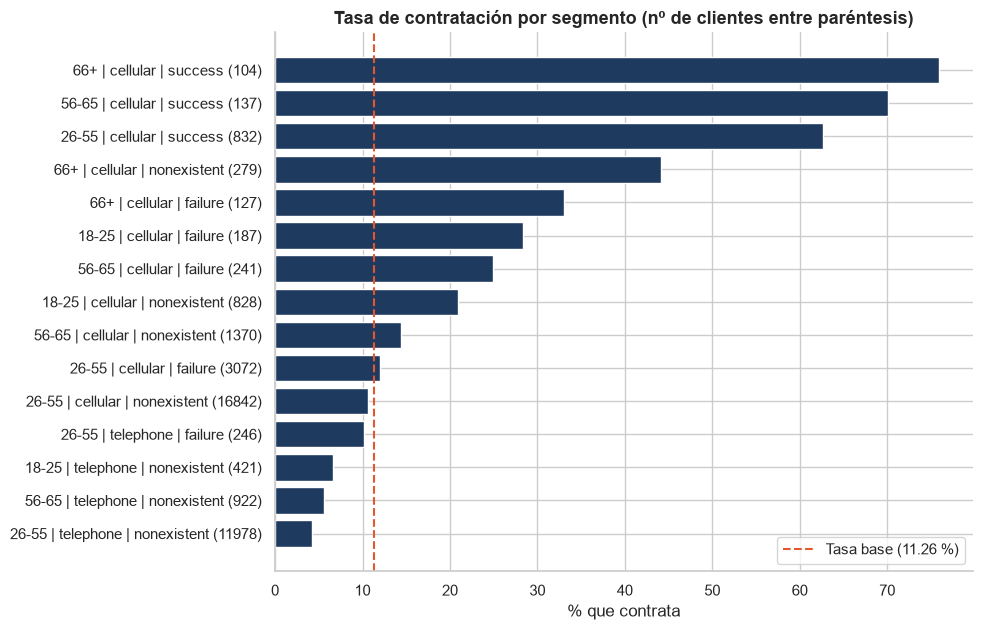

In [58]:
grafico = tabla_seg.reset_index().sort_values("tasa_yes")      # De menor a mayor: la barra más alta queda arriba

# Etiqueta de cada segmento: edad | canal | resultado anterior (nº de clientes)
grafico["segmento"] = (grafico["edad_gr"].astype(str) + " | " + grafico["contact"] + " | " +
                       grafico["poutcome"] + " (" + grafico["clientes"].astype(str) + ")")

plt.figure(figsize=(9, 7))
plt.barh(grafico["segmento"], grafico["tasa_yes"], color=COLOR_PRINCIPAL)
plt.axvline(tasa_base, color=COLOR_YES, linestyle="--",label=f"Tasa base ({tasa_base:.2f} %)")
plt.title("Tasa de contratación por segmento (nº de clientes entre paréntesis)")
plt.xlabel("% que contrata")
plt.legend()
plt.show()

Al combinar la edad (`edad_gr`), el canal (`contact`) y el resultado de la campaña anterior (`poutcome`) aparecen grupos de clientes que contratan mucho más que la media del 11,26 %. Los que ya contrataron en una campaña anterior y fueron contactados por móvil lo hacen entre el 62,62 % y el 75,96 % de las veces, según la edad. Los ocho segmentos con una tasa del 20 % o más son solo el 7,2 % de los clientes, pero aportan el 26,9 % de las contrataciones.

En el lado contrario están los clientes sin campaña anterior contactados por teléfono fijo: más de 13.000 clientes, más de un tercio del total, con una tasa de solo el 4,4 %. En esos mismos grupos de edad, el móvil contrata entre dos veces y media y tres
veces más que el fijo. Son asociaciones y no causas, y solo se muestran segmentos con al menos 100 clientes.

## 11. Conclusiones y recomendaciones



### 11.1 Conclusiones

Solo el 11,26 % de los clientes contrata el depósito (4.263 de 37.867), así que llamar sin criterio es poco eficiente. El análisis muestra que la contratación se relaciona sobre todo con el historial del cliente y con el canal de contacto. Los clientes que ya contrataron en una campaña anterior vuelven a hacerlo el 64,87 % de las veces, y los contactados por móvil contratan el 14,77 %, casi el triple que los contactados por teléfono fijo (5,11 %).

El perfil del cliente aporta menos. La edad tiene forma de "U": contratan más los mayores de 66 años (46,01 %) y los de 18 a 25 (20,85 %), y menos los de 36 a 55, en torno al 8,6 %. Entre los trabajos destacan los estudiantes (30,96 %) y los
jubilados (24,94 %). En cambio, los ingresos, tener hipoteca o préstamo y el mes o el año de la llamada no muestran relación con la contratación.

Sobre las llamadas, la tasa baja con cada contacto: del 12,93 % con uno al 5,52 % con seis o más, y el 75,5 % de las contrataciones se logra en los dos primeros contactos. La duración también se relaciona con contratar (ningún cliente contrata en llamadas demenos de un minuto y el 48,62 % lo hace en las de más de diez), pero solo se conoce al terminar la llamada y no sirve para decidir a quién llamar.

Al combinar edad, canal y resultado anterior, los ocho mejores grupos son el 7,2 % de los clientes y aportan el 26,9 % de las contrataciones.

### 11.2 Recomendaciones para marketing

- 1. Empezar las campañas por los clientes con éxito previo, sobre todo por móvil, porque son pocos pero rinden entre cinco y seis veces la media.

- 2. Priorizar el móvil sobre el teléfono fijo, especialmente con clientes sin historial, donde el móvil contrata entre dos veces y media y tres veces más.

- 3. Limitar la insistencia a unos tres contactos por cliente y dedicar las llamadas que sobran a clientes nuevos o con historial. 

- 4. Prestar atención a los extremos de edad, jóvenes de 18 a 25 y mayores de 66, y dejar de usar los ingresos, la hipoteca, el préstamo o el calendario para decidir a quién llamar, porque noo distinguen a quien contrata.


### 11.3 Limitaciones

- La duración de la llamada y el número de contactos de esta campaña solo se conocen una vez hecha la llamada, por lo que no sirven para predecir. 

- Algunas variables tienen datos ausentes que se mantuvieron como categoría `unknown` (por ejemplo, el 20,8 % de los clientes en`default`), y se excluyeron del análisis las categorías con muy pocos clientes.